In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

# Find the project root from either the repository root or notebooks/.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "processed").exists():
    candidates = [PROJECT_ROOT, *PROJECT_ROOT.parents]
    matches = [p for p in candidates if (p / "data" / "processed").exists()]
    if matches:
        PROJECT_ROOT = matches[0]

DATA_DIR = PROJECT_ROOT / "data" / "processed"
RAW_DIR = PROJECT_ROOT / "data" / "raw"
REPORT_DIR = PROJECT_ROOT / "reports" / "eda_processed"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Processed data:", DATA_DIR)
print("Raw data:", RAW_DIR)
print("EDA outputs:", REPORT_DIR)

if not DATA_DIR.exists():
    raise FileNotFoundError(
        "Could not find data/processed. Run this notebook from the repository "
        "root or place it inside the repository's notebooks/ directory."
    )

Project root: /Users/sarachhabra/Climate-Change-Awareness-Dashboard
Processed data: /Users/sarachhabra/Climate-Change-Awareness-Dashboard/data/processed
Raw data: /Users/sarachhabra/Climate-Change-Awareness-Dashboard/data/raw
EDA outputs: /Users/sarachhabra/Climate-Change-Awareness-Dashboard/reports/eda_processed


In [2]:
# Load source tables

annual_original = pd.read_csv(DATA_DIR / "climate_annual.csv")
annual = pd.read_csv(DATA_DIR / "climate_annual_reconstructed.csv")
drivers_original = pd.read_csv(DATA_DIR / "drivers_annual_full.csv")
drivers = pd.read_csv(DATA_DIR / "drivers_annual_full_reconstructed.csv")
monthly_original = pd.read_csv(DATA_DIR / "climate_monthly.csv")
monthly_original["date"] = pd.to_datetime(monthly_original["date"], errors="raise")
monthly_original = monthly_original.sort_values("date").reset_index(drop=True)

print("Annual original:", annual_original.shape)
print("Annual reconstructed:", annual.shape)
print("Full drivers original:", drivers_original.shape)
print("Full drivers reconstructed:", drivers.shape)
print("Monthly original:", monthly_original.shape)
print("Monthly period:", monthly_original["date"].min(), "to", monthly_original["date"].max())

# Backward-compatible alias for the existing annual EDA cells.
monthly = monthly_original.copy()

Annual original: (146, 8)
Annual reconstructed: (146, 22)
Full drivers original: (176, 7)
Full drivers reconstructed: (176, 21)
Monthly original: (822, 11)
Monthly period: 1958-03-01 00:00:00 to 2026-08-01 00:00:00


In [3]:

print("ANNUAL CLIMATE DATA")
print(annual.columns.tolist())
display(annual.head())
display(annual.dtypes)

print("\nANNUAL DRIVERS DATA")
print(drivers.columns.tolist())
display(drivers.head())
display(drivers.dtypes)

print("\nMONTHLY CLIMATE DATA")
print(monthly.columns.tolist())
display(monthly.head())


ANNUAL CLIMATE DATA
['year', 'temp_anomaly', 'co2', 'co2_source', 'sunspots', 'nino34', 'ch4', 'n2o', 'ch4_observed_noaa', 'ch4_data_status', 'ch4_is_synthetic', 'ch4_method_note', 'ch4_anchor_value', 'ch4_was_filled', 'ch4_final_status', 'n2o_observed_noaa', 'n2o_data_status', 'n2o_is_synthetic', 'n2o_method_note', 'n2o_anchor_value', 'n2o_was_filled', 'n2o_final_status']


,year,temp_anomaly,co2,co2_source,sunspots,nino34,ch4,n2o,ch4_observed_noaa,ch4_data_status,...,ch4_anchor_value,ch4_was_filled,ch4_final_status,n2o_observed_noaa,n2o_data_status,n2o_is_synthetic,n2o_method_note,n2o_anchor_value,n2o_was_filled,n2o_final_status
0,1880,-0.18,289.78,ice_core,53.7,NaN,823.54,275.655172,NaN,synthetic_linear_interpolation,...,NaN,True,synthetic_linear_interpolation,NaN,synthetic_linear_interpolation,True,historical_interpolation_from_very_sparse_EPA_...,NaN,True,synthetic_linear_interpolation
1,1881,-0.09,290.01,ice_core,90.5,NaN,824.78,275.810345,NaN,synthetic_linear_interpolation,...,NaN,True,synthetic_linear_interpolation,NaN,synthetic_linear_interpolation,True,historical_interpolation_from_very_sparse_EPA_...,NaN,True,synthetic_linear_interpolation
2,1882,-0.12,290.26,ice_core,99.0,NaN,826.02,275.965517,NaN,synthetic_linear_interpolation,...,NaN,True,synthetic_linear_interpolation,NaN,synthetic_linear_interpolation,True,historical_interpolation_from_very_sparse_EPA_...,NaN,True,synthetic_linear_interpolation
3,1883,-0.18,290.51,ice_core,106.1,NaN,827.26,276.120690,NaN,synthetic_linear_interpolation,...,NaN,True,synthetic_linear_interpolation,NaN,synthetic_linear_interpolation,True,historical_interpolation_from_very_sparse_EPA_...,NaN,True,synthetic_linear_interpolation
4,1884,-0.29,290.77,ice_core,105.8,NaN,828.50,276.275862,NaN,EPA_Law_Dome_historical_anchor,...,828.5,True,EPA_Law_Dome_historical_anchor,NaN,synthetic_linear_interpolation,True,historical_interpolation_from_very_sparse_EPA_...,NaN,True,synthetic_linear_interpolation


year                   int64
temp_anomaly         float64
co2                  float64
co2_source            object
sunspots             float64
nino34               float64
ch4                  float64
n2o                  float64
ch4_observed_noaa    float64
ch4_data_status       object
ch4_is_synthetic        bool
ch4_method_note       object
ch4_anchor_value     float64
ch4_was_filled          bool
ch4_final_status      object
n2o_observed_noaa    float64
n2o_data_status       object
n2o_is_synthetic        bool
n2o_method_note       object
n2o_anchor_value     float64
n2o_was_filled          bool
n2o_final_status      object
dtype: object


ANNUAL DRIVERS DATA
['year', 'co2', 'co2_source', 'sunspots', 'nino34', 'ch4', 'n2o', 'ch4_observed_noaa', 'ch4_data_status', 'ch4_is_synthetic', 'ch4_method_note', 'ch4_anchor_value', 'ch4_was_filled', 'ch4_final_status', 'n2o_observed_noaa', 'n2o_data_status', 'n2o_is_synthetic', 'n2o_method_note', 'n2o_anchor_value', 'n2o_was_filled', 'n2o_final_status']


,year,co2,co2_source,sunspots,nino34,ch4,n2o,ch4_observed_noaa,ch4_data_status,ch4_is_synthetic,...,ch4_anchor_value,ch4_was_filled,ch4_final_status,n2o_observed_noaa,n2o_data_status,n2o_is_synthetic,n2o_method_note,n2o_anchor_value,n2o_was_filled,n2o_final_status
0,1850,285.77,ice_core,126.3,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,False,missing_not_reconstructed,NaN,NaN,NaN,NaN,NaN,False,missing_not_reconstructed
1,1851,285.86,ice_core,122.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,False,missing_not_reconstructed,NaN,NaN,NaN,NaN,NaN,False,missing_not_reconstructed
2,1852,285.96,ice_core,102.7,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,False,missing_not_reconstructed,NaN,NaN,NaN,NaN,NaN,False,missing_not_reconstructed
3,1853,286.05,ice_core,74.1,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,False,missing_not_reconstructed,NaN,NaN,NaN,NaN,NaN,False,missing_not_reconstructed
4,1854,286.14,ice_core,39.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,False,missing_not_reconstructed,NaN,NaN,NaN,NaN,NaN,False,missing_not_reconstructed


year                   int64
co2                  float64
co2_source            object
sunspots             float64
nino34               float64
ch4                  float64
n2o                  float64
ch4_observed_noaa    float64
ch4_data_status       object
ch4_is_synthetic      object
ch4_method_note       object
ch4_anchor_value     float64
ch4_was_filled          bool
ch4_final_status      object
n2o_observed_noaa    float64
n2o_data_status       object
n2o_is_synthetic      object
n2o_method_note       object
n2o_anchor_value     float64
n2o_was_filled          bool
n2o_final_status      object
dtype: object


MONTHLY CLIMATE DATA
['date', 'temp_anomaly', 'co2_monthly', 'co2_trend', 'sunspots', 'sunspots_definitive', 'nino34', 'ch4', 'ch4_trend', 'n2o', 'n2o_trend']


,date,temp_anomaly,co2_monthly,co2_trend,sunspots,sunspots_definitive,nino34,ch4,ch4_trend,n2o,n2o_trend
0,1958-03-01,0.08,315.71,314.44,270.0,1,1.26,NaN,NaN,NaN,NaN
1,1958-04-01,0.01,317.45,315.16,277.6,1,0.81,NaN,NaN,NaN,NaN
2,1958-05-01,0.06,317.51,314.69,248.2,1,0.71,NaN,NaN,NaN,NaN
3,1958-06-01,-0.09,317.27,315.15,242.9,1,0.69,NaN,NaN,NaN,NaN
4,1958-07-01,0.05,315.87,315.20,271.0,1,0.51,NaN,NaN,NaN,NaN


In [4]:

datasets = {
    "annual_climate": annual,
    "annual_drivers": drivers,
    "monthly_climate": monthly
}

for name, df in datasets.items():
    print(f"\n{'=' * 55}")
    print(name.upper())
    print("=" * 55)

    print("Rows:", len(df))
    print("Columns:", len(df.columns))
    print("Duplicate rows:", df.duplicated().sum())

    print("\nMissing values:")
    missing = df.isna().sum()
    missing = missing[missing > 0]
    display(missing.sort_values(ascending=False))

    print("\nData types:")
    display(df.dtypes)



ANNUAL_CLIMATE
Rows: 146
Columns: 22
Duplicate rows: 0

Missing values:


n2o_observed_noaa    121
n2o_anchor_value     120
ch4_observed_noaa    104
ch4_anchor_value      80
nino34                70
dtype: int64


Data types:


year                   int64
temp_anomaly         float64
co2                  float64
co2_source            object
sunspots             float64
nino34               float64
ch4                  float64
n2o                  float64
ch4_observed_noaa    float64
ch4_data_status       object
ch4_is_synthetic        bool
ch4_method_note       object
ch4_anchor_value     float64
ch4_was_filled          bool
ch4_final_status      object
n2o_observed_noaa    float64
n2o_data_status       object
n2o_is_synthetic        bool
n2o_method_note       object
n2o_anchor_value     float64
n2o_was_filled          bool
n2o_final_status      object
dtype: object


ANNUAL_DRIVERS
Rows: 176
Columns: 21
Duplicate rows: 0

Missing values:


...

year                   int64
co2                  float64
co2_source            object
sunspots             float64
nino34               float64
ch4                  float64
n2o                  float64
ch4_observed_noaa    float64
ch4_data_status       object
ch4_is_synthetic      object
ch4_method_note       object
ch4_anchor_value     float64
ch4_was_filled          bool
ch4_final_status      object
n2o_observed_noaa    float64
n2o_data_status       object
n2o_is_synthetic      object
n2o_method_note       object
n2o_anchor_value     float64
n2o_was_filled          bool
n2o_final_status      object
dtype: object


MONTHLY_CLIMATE
Rows: 822
Columns: 11
Duplicate rows: 0

Missing values:


n2o          516
n2o_trend    516
ch4          306
ch4_trend    306
nino34         2
dtype: int64


Data types:


date                   datetime64[ns]
temp_anomaly                  float64
co2_monthly                   float64
co2_trend                     float64
sunspots                      float64
sunspots_definitive             int64
nino34                        float64
ch4                           float64
ch4_trend                     float64
n2o                           float64
n2o_trend                     float64
dtype: object

In [5]:

for name, df in datasets.items():
    print(f"\n{name.upper()}")

    year_columns = [
        col for col in df.columns
        if col.strip().lower() in ["year", "date", "time"]
    ]

    if not year_columns:
        print("No obvious year/date column found.")
        continue

    col = year_columns[0]

    print("Date/year column:", col)
    print("First values:", df[col].head().tolist())
    print("Last values:", df[col].tail().tolist())
    print("Duplicate date/year values:", df[col].duplicated().sum())



ANNUAL_CLIMATE
Date/year column: year
First values: [1880, 1881, 1882, 1883, 1884]
Last values: [2021, 2022, 2023, 2024, 2025]
Duplicate date/year values: 0

ANNUAL_DRIVERS
Date/year column: year
First values: [1850, 1851, 1852, 1853, 1854]
Last values: [2021, 2022, 2023, 2024, 2025]
Duplicate date/year values: 0

MONTHLY_CLIMATE
Date/year column: date
First values: [Timestamp('1958-03-01 00:00:00'), Timestamp('1958-04-01 00:00:00'), Timestamp('1958-05-01 00:00:00'), Timestamp('1958-06-01 00:00:00'), Timestamp('1958-07-01 00:00:00')]
Last values: [Timestamp('2026-04-01 00:00:00'), Timestamp('2026-05-01 00:00:00'), Timestamp('2026-06-01 00:00:00'), Timestamp('2026-07-01 00:00:00'), Timestamp('2026-08-01 00:00:00')]
Duplicate date/year values: 0


In [6]:

print("ANNUAL CLIMATE — DESCRIPTIVE STATISTICS")
display(annual.describe(include="all").T)

print("\nANNUAL DRIVERS — DESCRIPTIVE STATISTICS")
display(drivers.describe(include="all").T)

print("\nMONTHLY CLIMATE — DESCRIPTIVE STATISTICS")
display(monthly.describe(include="all").T)



ANNUAL CLIMATE — DESCRIPTIVE STATISTICS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
year,146.0,NaN,NaN,NaN,1952.5,42.290661,1880.0,1916.25,1952.5,1988.75,2025.0
temp_anomaly,146.0,NaN,NaN,NaN,0.081233,0.402542,-0.49,-0.2,-0.03,0.3175,1.29
co2,146.0,NaN,NaN,NaN,329.429658,37.261341,289.78,301.735,312.625,352.8225,427.35
co2_source,146,2,ice_core,79,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sunspots,146.0,NaN,NaN,NaN,83.631507,63.881491,2.4,25.6,73.6,124.925,269.3
nino34,76.0,NaN,NaN,NaN,0.026393,0.622497,-1.224167,-0.466042,0.055,0.452708,1.545833
ch4,146.0,NaN,NaN,NaN,1277.877409,378.783285,823.54,927.825,1123.115,1701.695,1936.03
n2o,146.0,NaN,NaN,NaN,296.815274,17.789908,275.655172,281.280172,292.216094,310.261797,338.86
ch4_observed_noaa,42.0,NaN,NaN,NaN,1786.9,73.024642,1644.84,1743.765,1776.035,1831.29,1936.03
ch4_data_status,146,3,synthetic_linear_interpolation,80,NaN,NaN,NaN,NaN,NaN,NaN,NaN



ANNUAL DRIVERS — DESCRIPTIVE STATISTICS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
year,176.0,NaN,NaN,NaN,1937.5,50.950957,1850.0,1893.75,1937.5,1981.25,2025.0
co2,176.0,NaN,NaN,NaN,322.25483,37.450769,285.77,293.785,309.175,340.46,427.35
co2_source,176,2,ice_core,109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sunspots,176.0,NaN,NaN,NaN,83.968182,63.571009,2.4,26.6,74.3,124.075,269.3
nino34,76.0,NaN,NaN,NaN,0.026393,0.622497,-1.224167,-0.466042,0.055,0.452708,1.545833
ch4,146.0,NaN,NaN,NaN,1277.877409,378.783285,823.54,927.825,1123.115,1701.695,1936.03
n2o,146.0,NaN,NaN,NaN,296.815274,17.789908,275.655172,281.280172,292.216094,310.261797,338.86
ch4_observed_noaa,42.0,NaN,NaN,NaN,1786.9,73.024642,1644.84,1743.765,1776.035,1831.29,1936.03
ch4_data_status,146,3,synthetic_linear_interpolation,80,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ch4_is_synthetic,146,2,True,80,NaN,NaN,NaN,NaN,NaN,NaN,NaN



MONTHLY CLIMATE — DESCRIPTIVE STATISTICS


,count,mean,min,25%,50%,75%,max,std
date,822,1992-05-16 15:23:12.700729984,1958-03-01 00:00:00,1975-04-08 12:00:00,1992-05-16 12:00:00,2009-06-23 12:00:00,2026-08-01 00:00:00,NaN
temp_anomaly,822.0,0.40281,-0.35,0.08,0.35,0.67,1.48,0.389011
co2_monthly,822.0,361.360474,312.42,331.2825,356.36,387.6825,432.34,33.45619
co2_trend,822.0,361.349088,314.44,330.8825,356.49,387.7125,429.51,33.387729
sunspots,822.0,89.685766,0.0,27.3,75.0,137.325,307.7,70.498945
sunspots_definitive,822.0,0.997567,0.0,1.0,1.0,1.0,1.0,0.049296
nino34,820.0,0.035341,-2.09,-0.53,-0.02,0.5125,2.77,0.853195
ch4,516.0,1786.982674,1625.96,1741.235,1777.36,1834.745,1945.51,75.202624
ch4_trend,516.0,1786.984729,1635.11,1740.87,1775.215,1836.7575,1942.12,75.060299
n2o,306.0,326.806503,316.11,320.2725,326.125,332.5475,339.86,7.060871


In [7]:

for name, df in {
    "annual_climate": annual,
    "annual_drivers": drivers
}.items():
    print(f"\n{name.upper()}")

    flag_columns = [
        col for col in df.columns
        if any(term in col.lower() for term in [
            "synthetic", "interpol", "observed",
            "reconstruct", "method", "source"
        ])
    ]

    if flag_columns:
        display(df[flag_columns].head())
        for col in flag_columns:
            print(f"\n{col}:")
            display(df[col].value_counts(dropna=False))
    else:
        print("No obvious reconstruction/observation flags found.")



ANNUAL_CLIMATE


,co2_source,ch4_observed_noaa,ch4_is_synthetic,ch4_method_note,n2o_observed_noaa,n2o_is_synthetic,n2o_method_note
0,ice_core,NaN,True,historical_interpolation_from_sparse_EPA_Law_D...,NaN,True,historical_interpolation_from_very_sparse_EPA_...
1,ice_core,NaN,True,historical_interpolation_from_sparse_EPA_Law_D...,NaN,True,historical_interpolation_from_very_sparse_EPA_...
2,ice_core,NaN,True,historical_interpolation_from_sparse_EPA_Law_D...,NaN,True,historical_interpolation_from_very_sparse_EPA_...
3,ice_core,NaN,True,historical_interpolation_from_sparse_EPA_Law_D...,NaN,True,historical_interpolation_from_very_sparse_EPA_...
4,ice_core,NaN,False,historical_interpolation_from_sparse_EPA_Law_D...,NaN,True,historical_interpolation_from_very_sparse_EPA_...



co2_source:


co2_source
ice_core     79
mauna_loa    67
Name: count, dtype: int64


ch4_observed_noaa:


...

n2o_observed_noaa
NaN       151
316.36      1
337.72      1
336.70      1
335.63      1
334.29      1
333.01      1
331.88      1
330.90      1
329.74      1
328.95      1
328.17      1
327.09      1
325.94      1
325.05      1
324.21      1
323.18      1
322.27      1
321.50      1
320.44      1
319.82      1
318.91      1
318.25      1
317.63      1
316.94      1
338.86      1
Name: count, dtype: int64


n2o_is_synthetic:


n2o_is_synthetic
True     120
NaN       30
False     26
Name: count, dtype: int64


n2o_method_note:


n2o_method_note
synthetic_bridge_1938_2000_no_NOAA_global_annual_data          63
historical_interpolation_from_very_sparse_EPA_EPICA_anchors    58
NaN                                                            30
piecewise_linear_between_anchors                               25
Name: count, dtype: int64

In [8]:

print("Columns available:", annual.columns.tolist())

target_candidates = [
    col for col in annual.columns
    if any(term in col.lower() for term in [
        "anomaly", "temperature", "temp"
    ])
    and pd.api.types.is_numeric_dtype(annual[col])
]

print("Possible temperature columns:", target_candidates)


Columns available: ['year', 'temp_anomaly', 'co2', 'co2_source', 'sunspots', 'nino34', 'ch4', 'n2o', 'ch4_observed_noaa', 'ch4_data_status', 'ch4_is_synthetic', 'ch4_method_note', 'ch4_anchor_value', 'ch4_was_filled', 'ch4_final_status', 'n2o_observed_noaa', 'n2o_data_status', 'n2o_is_synthetic', 'n2o_method_note', 'n2o_anchor_value', 'n2o_was_filled', 'n2o_final_status']
Possible temperature columns: ['temp_anomaly']


In [9]:

print("Annual climate duplicate years:",
      annual["year"].duplicated().sum())

print("Annual drivers duplicate years:",
      drivers["year"].duplicated().sum())

monthly["date"] = pd.to_datetime(monthly["date"], errors="coerce")

print("Monthly duplicate dates:",
      monthly["date"].duplicated().sum())

print("Invalid monthly dates:",
      monthly["date"].isna().sum())


Annual climate duplicate years: 0
Annual drivers duplicate years: 0
Monthly duplicate dates: 0
Invalid monthly dates: 0


In [10]:

for name, df in datasets.items():
    missing_report = (
        df.isna()
        .sum()
        .rename("missing_count")
        .to_frame()
    )
    missing_report["missing_percent"] = (
        missing_report["missing_count"] / len(df) * 100
    ).round(2)

    missing_report.to_csv(
        REPORT_DIR / f"{name}_missingness.csv"
    )

    df.describe(include="all").T.to_csv(
        REPORT_DIR / f"{name}_descriptive_statistics.csv"
    )

print("EDA audit reports saved to:", REPORT_DIR)


EDA audit reports saved to: /Users/sarachhabra/Climate-Change-Awareness-Dashboard/reports/eda_processed


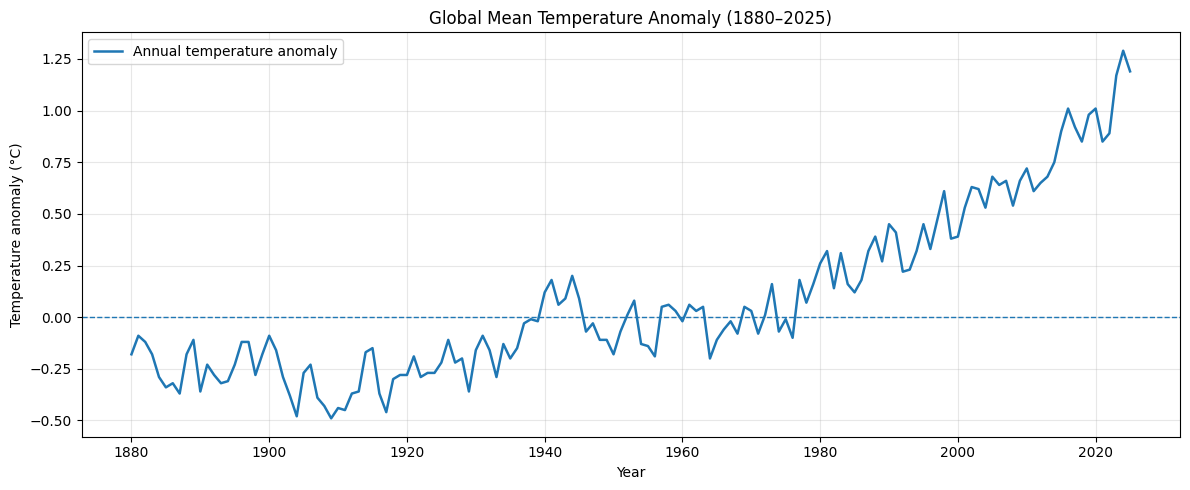

In [11]:

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    annual["year"],
    annual["temp_anomaly"],
    linewidth=1.8,
    label="Annual temperature anomaly"
)

ax.axhline(0, linestyle="--", linewidth=1)
ax.set_title("Global Mean Temperature Anomaly (1880–2025)")
ax.set_xlabel("Year")
ax.set_ylabel("Temperature anomaly (°C)")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
fig.savefig(
    REPORT_DIR / "global_temperature_anomaly.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


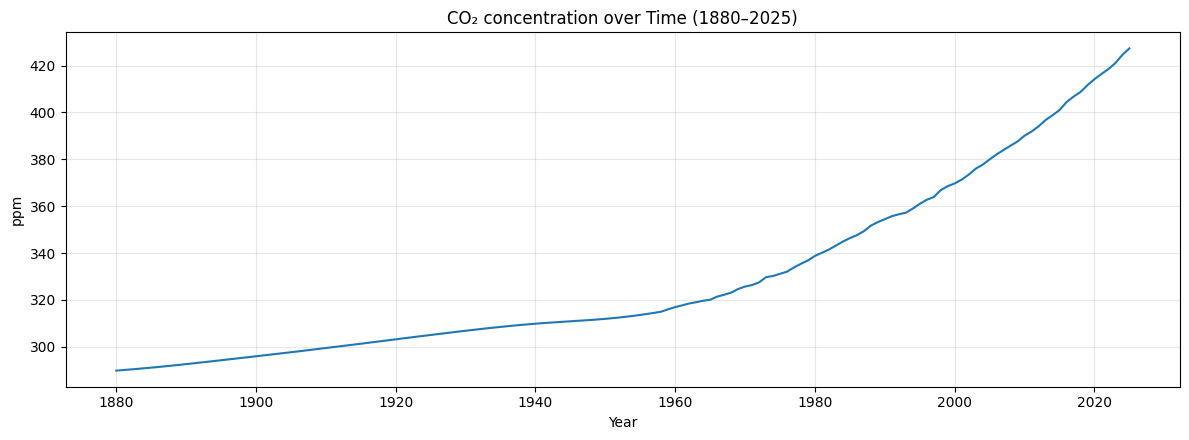

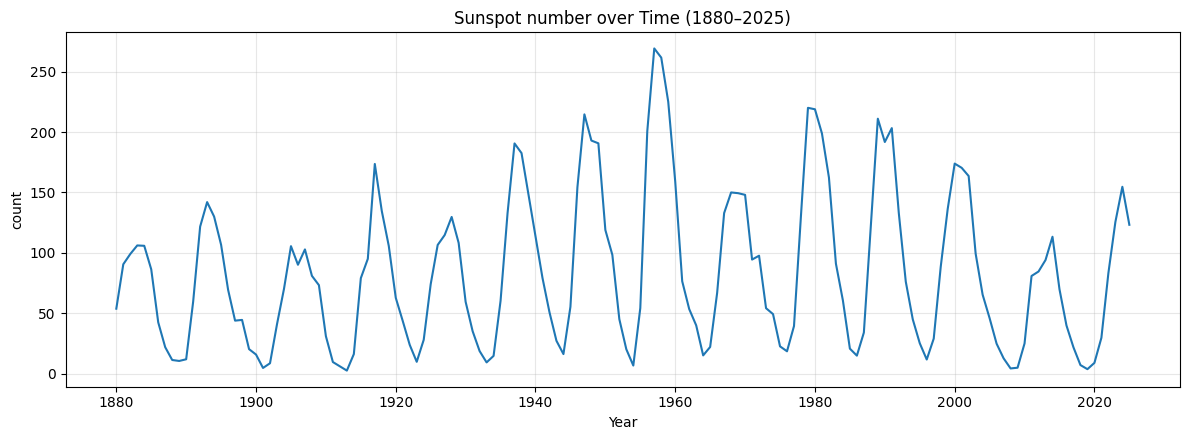

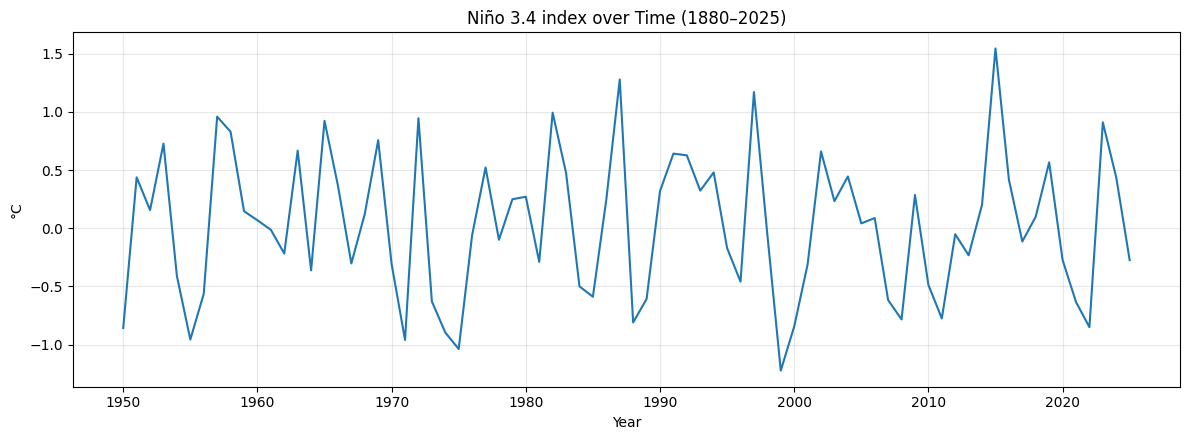

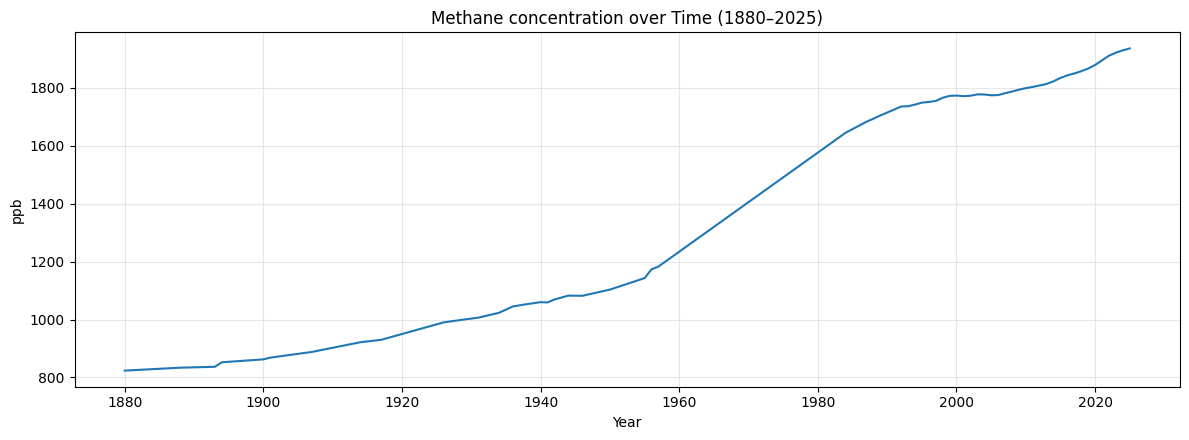

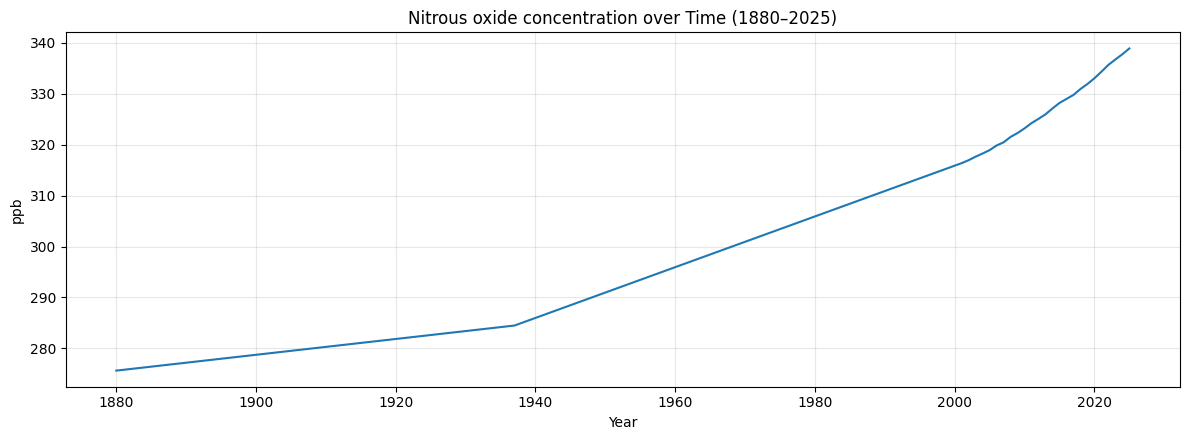

In [12]:

# Annual climate-driver time series
variables = {
    "co2": ("CO₂ concentration", "ppm"),
    "sunspots": ("Sunspot number", "count"),
    "nino34": ("Niño 3.4 index", "°C"),
    "ch4": ("Methane concentration", "ppb"),
    "n2o": ("Nitrous oxide concentration", "ppb"),
}

for col, (title, unit) in variables.items():
    fig, ax = plt.subplots(figsize=(12, 4.5))

    ax.plot(annual["year"], annual[col], linewidth=1.5)

    ax.set_title(f"{title} over Time (1880–2025)")
    ax.set_xlabel("Year")
    ax.set_ylabel(unit)
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    fig.savefig(
        REPORT_DIR / f"{col}_annual_timeseries.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)


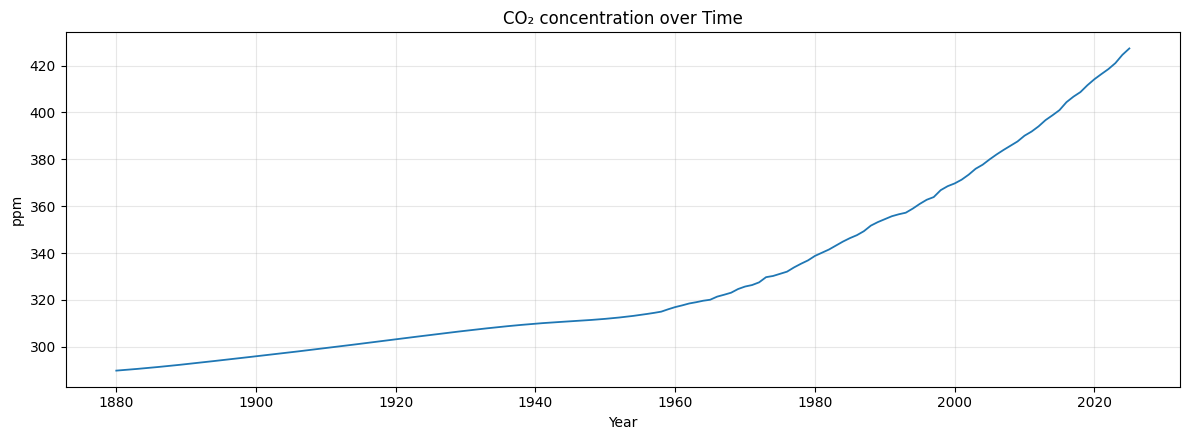

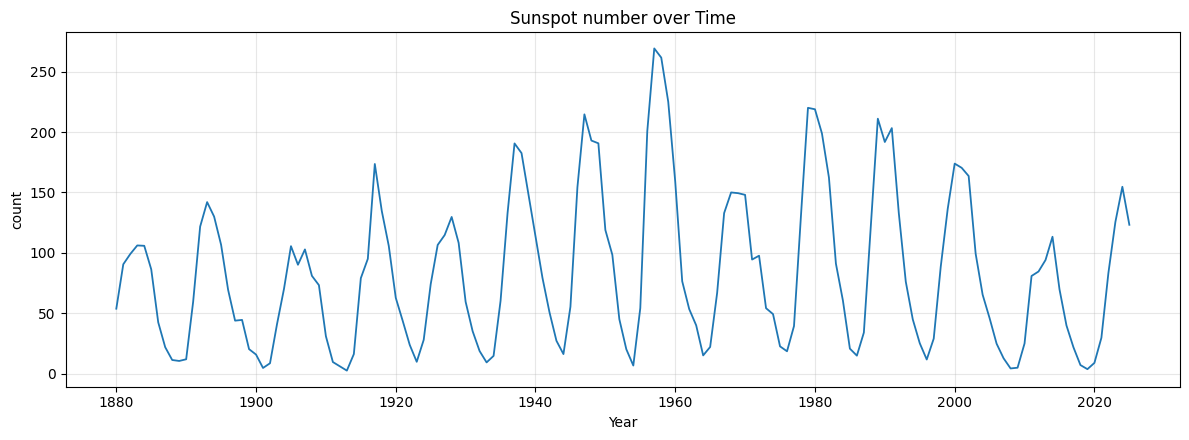

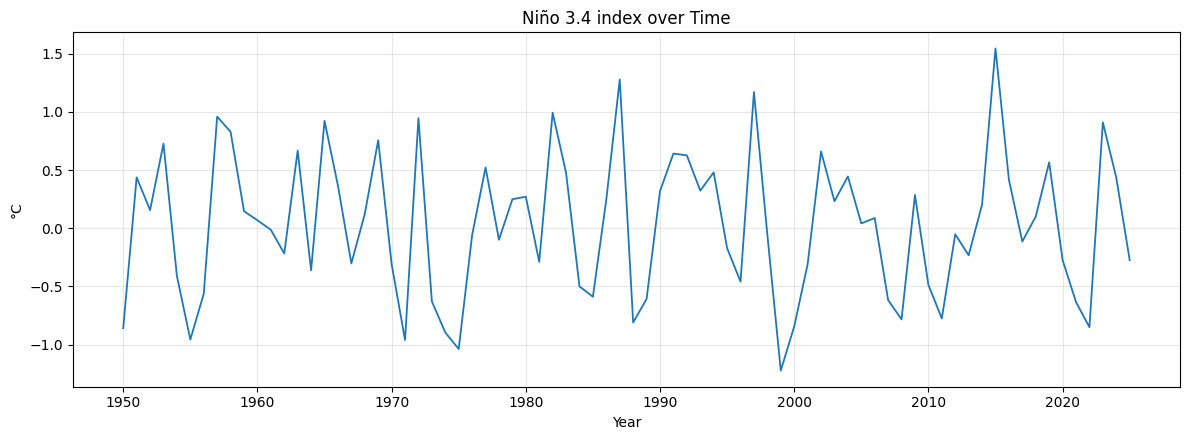

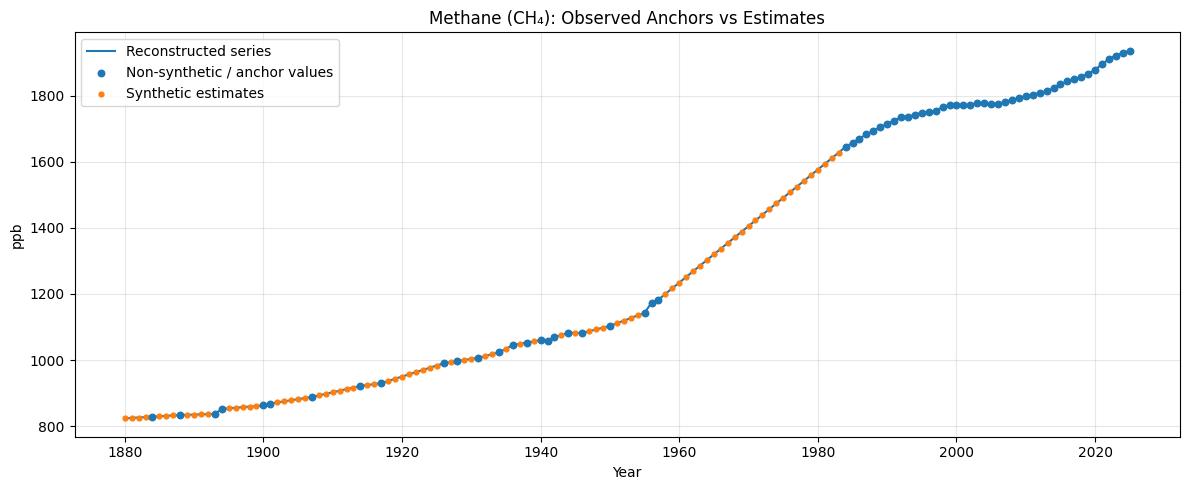

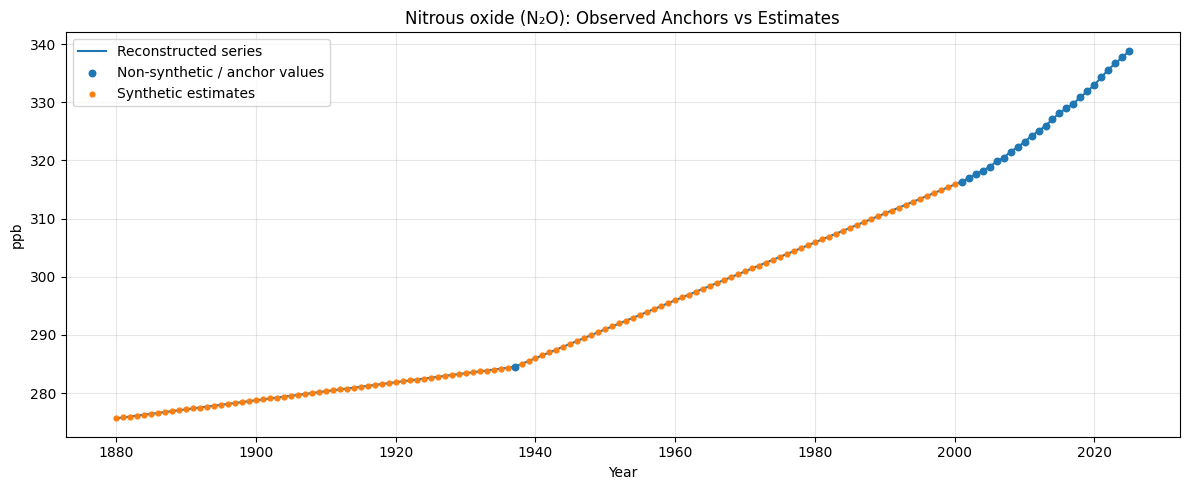

In [13]:

# Plot annual climate drivers, distinguishing observed anchors
# from synthetic CH4 and N2O estimates.

variables = {
    "co2": ("CO₂ concentration", "ppm"),
    "sunspots": ("Sunspot number", "count"),
    "nino34": ("Niño 3.4 index", "°C"),
}

for col, (title, unit) in variables.items():
    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.plot(annual["year"], annual[col], linewidth=1.3)
    ax.set_title(f"{title} over Time")
    ax.set_xlabel("Year")
    ax.set_ylabel(unit)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    fig.savefig(REPORT_DIR / f"{col}_annual_timeseries.png",
                dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# CH4 and N2O: display reconstructed series and mark anchors.
for gas, label, unit in [
    ("ch4", "Methane (CH₄)", "ppb"),
    ("n2o", "Nitrous oxide (N₂O)", "ppb"),
]:
    fig, ax = plt.subplots(figsize=(12, 5))

    ax.plot(
        annual["year"], annual[gas],
        linewidth=1.5, label="Reconstructed series"
    )

    synthetic_col = f"{gas}_is_synthetic"
    synthetic = annual[synthetic_col].fillna(False).astype(bool)

    # Non-synthetic values are plotted separately as anchor points.
    observed = annual[gas].notna() & ~synthetic
    estimated = annual[gas].notna() & synthetic

    ax.scatter(
        annual.loc[observed, "year"],
        annual.loc[observed, gas],
        s=22, label="Non-synthetic / anchor values", zorder=3
    )

    ax.scatter(
        annual.loc[estimated, "year"],
        annual.loc[estimated, gas],
        s=12, label="Synthetic estimates", zorder=2
    )

    ax.set_title(f"{label}: Observed Anchors vs Estimates")
    ax.set_xlabel("Year")
    ax.set_ylabel(unit)
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    fig.savefig(
        REPORT_DIR / f"{gas}_annual_observed_vs_estimated.png",
        dpi=150, bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)


In [14]:

for filename in [
    "climate_annual.csv",
    "climate_annual_reconstructed.csv",
    "drivers_annual_full.csv",
    "drivers_annual_full_reconstructed.csv",
    "climate_monthly.csv",
]:
    df = pd.read_csv(DATA_DIR / filename)

    print(f"\n{filename}")
    print("Shape:", df.shape)
    print("Missing CH4:", df["ch4"].isna().sum() if "ch4" in df else "N/A")
    print("Missing N2O:", df["n2o"].isna().sum() if "n2o" in df else "N/A")
    print("Total missing cells:", df.isna().sum().sum())



climate_annual.csv
Shape: (146, 8)
Missing CH4: 104
Missing N2O: 121
Total missing cells: 295

climate_annual_reconstructed.csv
Shape: (146, 22)
Missing CH4: 0
Missing N2O: 0
Total missing cells: 495

drivers_annual_full.csv
Shape: (176, 7)
Missing CH4: 134
Missing N2O: 151
Total missing cells: 385

drivers_annual_full_reconstructed.csv
Shape: (176, 21)
Missing CH4: 30
Missing N2O: 30
Total missing cells: 885

climate_monthly.csv
Shape: (822, 11)
Missing CH4: 306
Missing N2O: 516
Total missing cells: 1646


In [15]:

drivers_reconstructed = pd.read_csv(
    DATA_DIR / "drivers_annual_full_reconstructed.csv"
)

# Show the exact years with missing reconstructed greenhouse gases.
missing_ghg = drivers_reconstructed.loc[
    drivers_reconstructed["ch4"].isna()
    | drivers_reconstructed["n2o"].isna(),
    ["year", "ch4", "n2o"]
]

print("Years with missing CH4 or N2O:")
display(missing_ghg)

print("Missing CH4 years:",
      drivers_reconstructed.loc[
          drivers_reconstructed["ch4"].isna(), "year"
      ].tolist())

print("Missing N2O years:",
      drivers_reconstructed.loc[
          drivers_reconstructed["n2o"].isna(), "year"
      ].tolist())


Years with missing CH4 or N2O:


,year,ch4,n2o
0,1850,NaN,NaN
1,1851,NaN,NaN
2,1852,NaN,NaN
3,1853,NaN,NaN
4,1854,NaN,NaN
5,1855,NaN,NaN
6,1856,NaN,NaN
7,1857,NaN,NaN
8,1858,NaN,NaN
9,1859,NaN,NaN


Missing CH4 years: [1850, 1851, 1852, 1853, 1854, 1855, 1856, 1857, 1858, 1859, 1860, 1861, 1862, 1863, 1864, 1865, 1866, 1867, 1868, 1869, 1870, 1871, 1872, 1873, 1874, 1875, 1876, 1877, 1878, 1879]
Missing N2O years: [1850, 1851, 1852, 1853, 1854, 1855, 1856, 1857, 1858, 1859, 1860, 1861, 1862, 1863, 1864, 1865, 1866, 1867, 1868, 1869, 1870, 1871, 1872, 1873, 1874, 1875, 1876, 1877, 1878, 1879]


In [16]:

missing_audit = pd.DataFrame({
    "missing_count": annual.isna().sum(),
    "missing_percent": (annual.isna().mean() * 100).round(2),
    "dtype": annual.dtypes.astype(str)
}).sort_values("missing_percent", ascending=False)

display(missing_audit)

missing_audit.to_csv(
    REPORT_DIR / "annual_missingness_audit.csv"
)


,missing_count,missing_percent,dtype
n2o_observed_noaa,121,82.88,float64
n2o_anchor_value,120,82.19,float64
ch4_observed_noaa,104,71.23,float64
ch4_anchor_value,80,54.79,float64
nino34,70,47.95,float64
year,0,0.00,int64
n2o_was_filled,0,0.00,bool
n2o_method_note,0,0.00,object
n2o_is_synthetic,0,0.00,bool
n2o_data_status,0,0.00,object


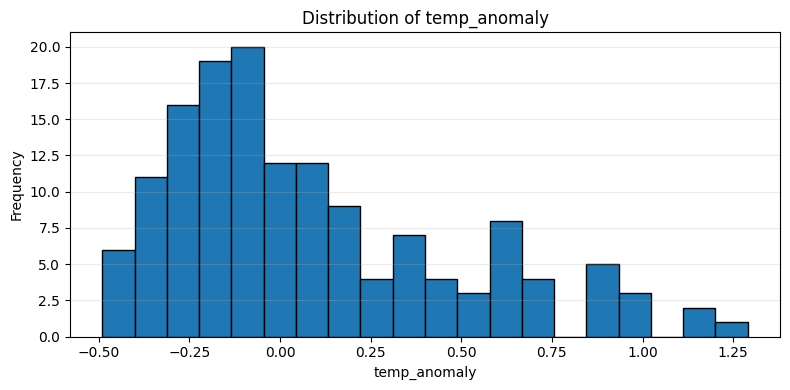

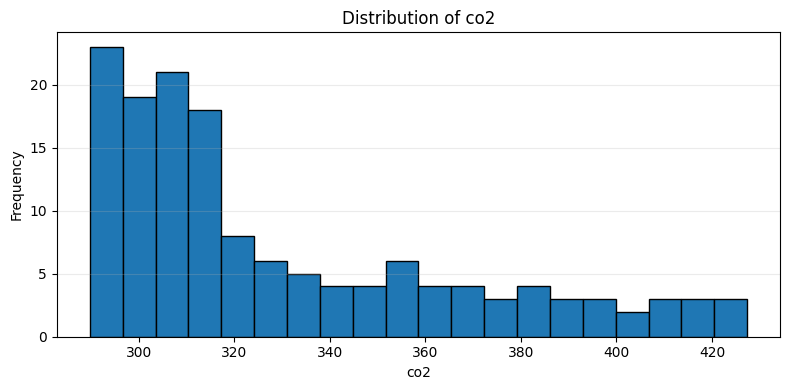

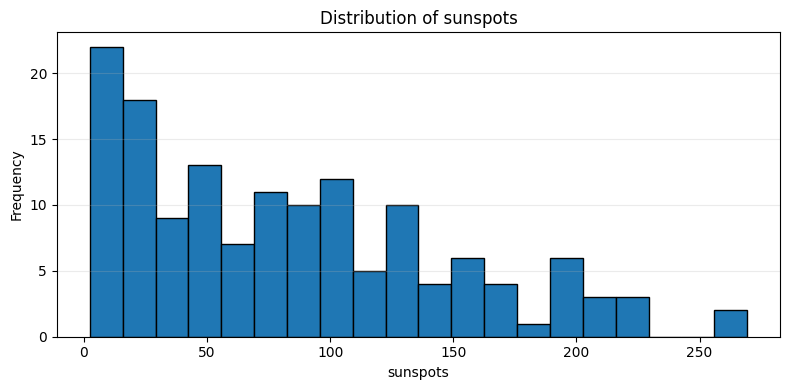

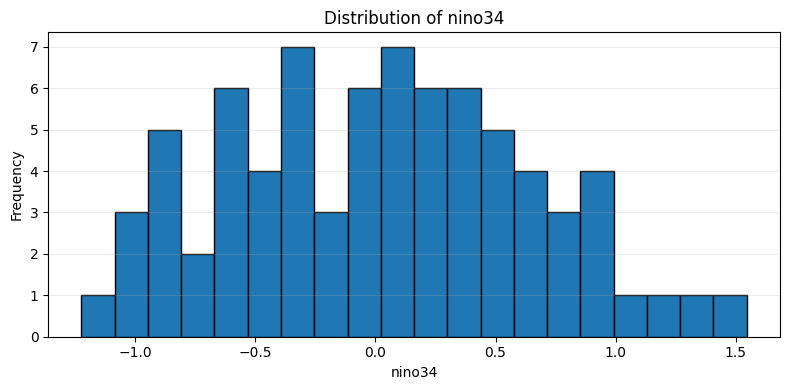

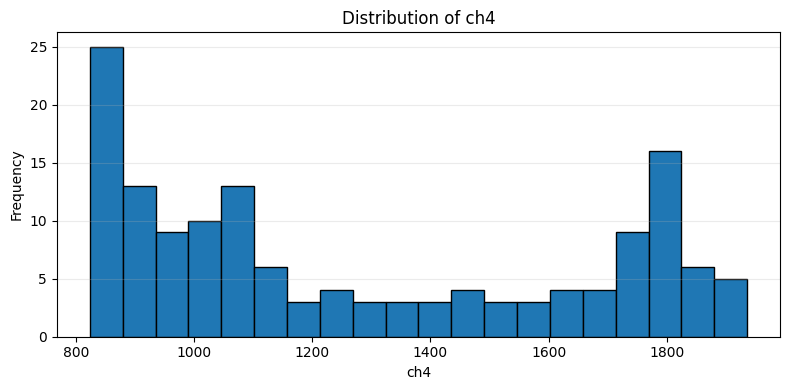

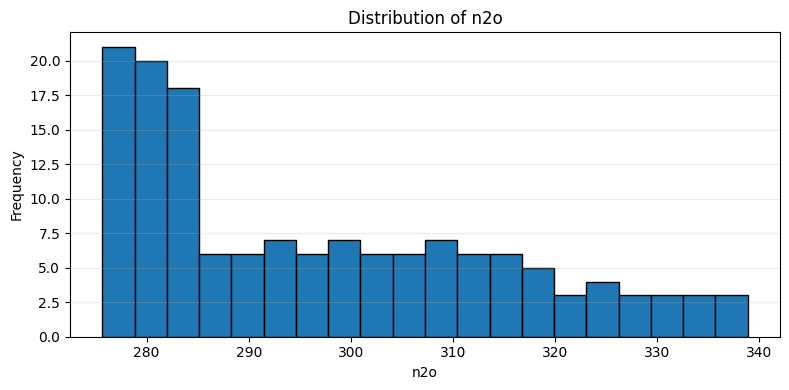

In [17]:

numeric_cols = [
    col for col in [
        "temp_anomaly", "co2", "sunspots",
        "nino34", "ch4", "n2o"
    ]
    if col in annual.columns
]

for col in numeric_cols:
    values = annual[col].dropna()

    fig, ax = plt.subplots(figsize=(8, 4))

    ax.hist(values, bins=20, edgecolor="black")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()
    fig.savefig(
        REPORT_DIR / f"{col}_distribution.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)


## Annual correlation analysis (exploratory)

This heatmap uses `climate_annual_reconstructed.csv`. CH₄/N₂O may include synthetic reconstructed annual values, so correlations involving those variables are exploratory and inherit reconstruction uncertainty. Correlation is not causation; trending time series can produce spurious level correlations. The first-difference heatmap below is a complementary diagnostic, not a full time-series causal analysis.



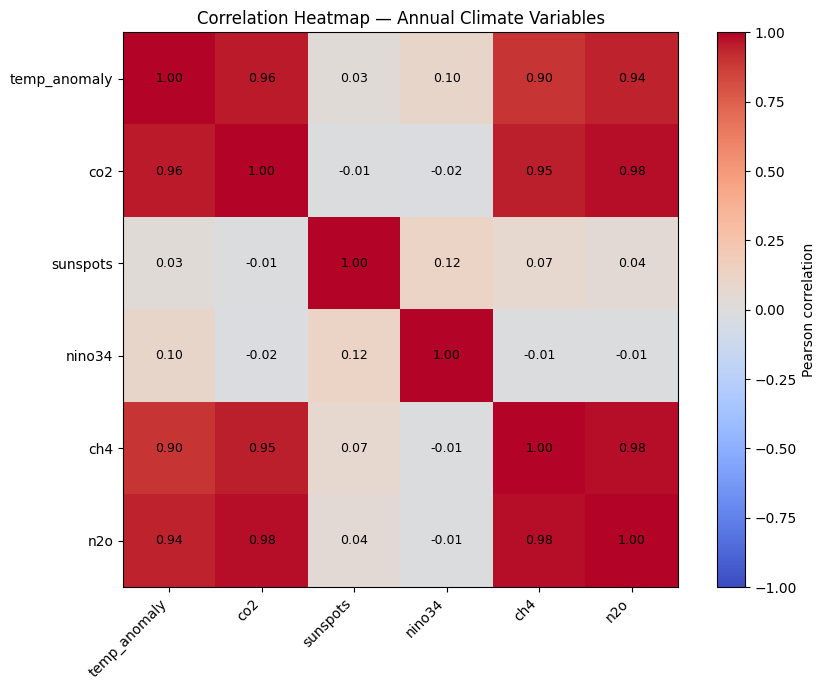

In [18]:

import matplotlib.pyplot as plt

corr_cols = [
    "temp_anomaly", "co2", "sunspots",
    "nino34", "ch4", "n2o"
]

corr_cols = [c for c in corr_cols if c in annual.columns]

corr = annual[corr_cols].corr(method="pearson")

fig, ax = plt.subplots(figsize=(9, 7))

image = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")

ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        value = corr.iloc[i, j]
        label = f"{value:.2f}" if pd.notna(value) else "N/A"
        ax.text(j, i, label, ha="center", va="center", fontsize=9)

fig.colorbar(image, ax=ax, label="Pearson correlation")
ax.set_title("Correlation Heatmap — Annual Climate Variables")

plt.tight_layout()
fig.savefig(
    REPORT_DIR / "annual_correlation_heatmap.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

corr.to_csv(REPORT_DIR / "annual_correlation_matrix.csv")


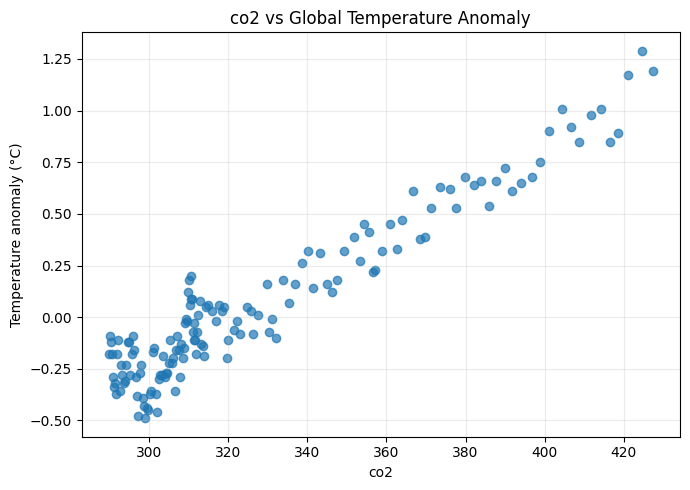

co2: 146 complete observations


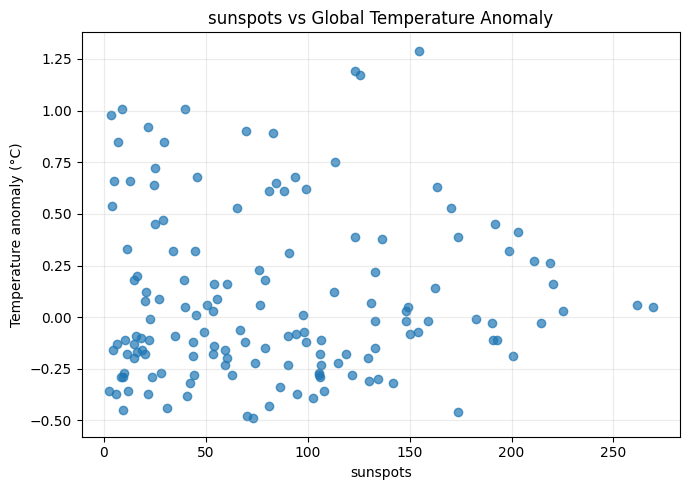

sunspots: 146 complete observations


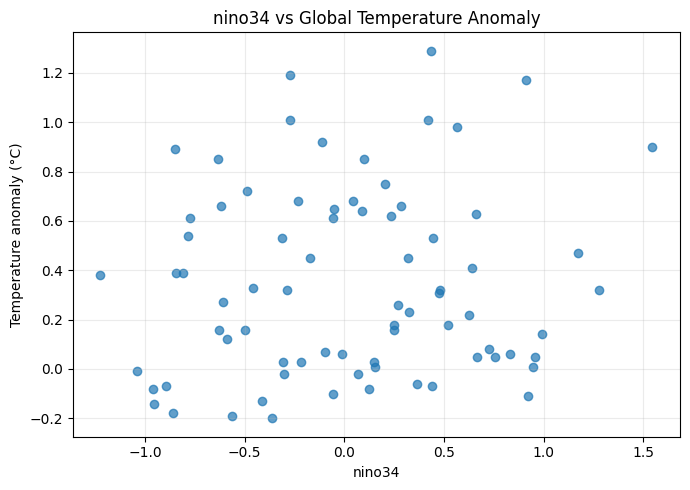

nino34: 76 complete observations


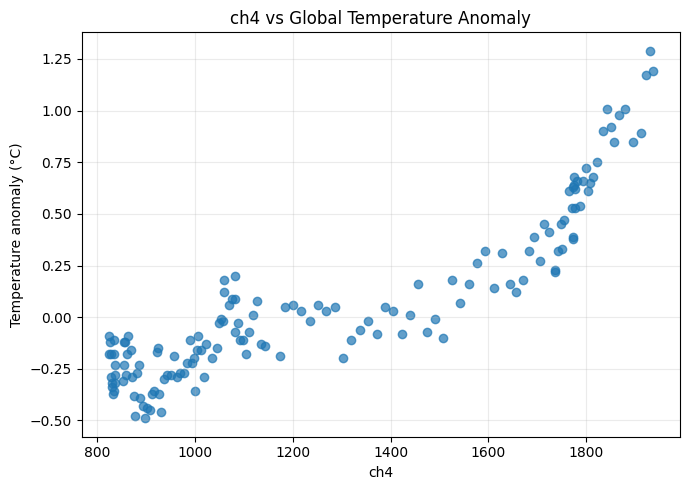

ch4: 146 complete observations


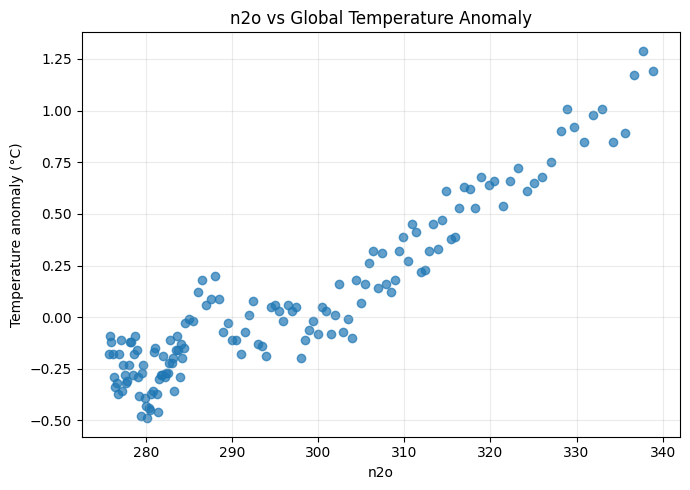

n2o: 146 complete observations


In [19]:
# Exploratory scatterplots. These show association only, not causation.
# CH4/N2O points may include reconstructed annual estimates; interpret accordingly.

target = "temp_anomaly"

drivers_to_plot = [
    "co2", "sunspots", "nino34", "ch4", "n2o"
]

drivers_to_plot = [
    c for c in drivers_to_plot
    if c in annual.columns
]

for col in drivers_to_plot:
    plot_data = annual[[col, target]].dropna()

    fig, ax = plt.subplots(figsize=(7, 5))

    ax.scatter(
        plot_data[col],
        plot_data[target],
        alpha=0.7
    )

    ax.set_title(f"{col} vs Global Temperature Anomaly")
    ax.set_xlabel(col)
    ax.set_ylabel("Temperature anomaly (°C)")
    ax.grid(True, alpha=0.25)

    plt.tight_layout()
    fig.savefig(
        REPORT_DIR / f"{col}_vs_temperature_scatter.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    print(f"{col}: {len(plot_data)} complete observations")


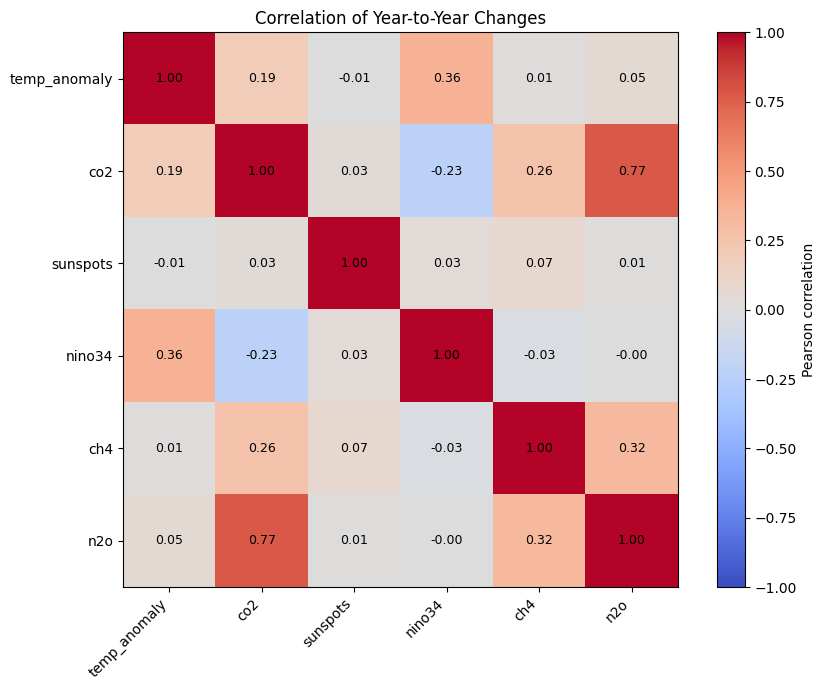

In [20]:

change_cols = [
    "temp_anomaly", "co2", "sunspots",
    "nino34", "ch4", "n2o"
]
change_cols = [c for c in change_cols if c in annual.columns]

annual_sorted = annual.sort_values("year").copy()

# First differences: current year minus previous year.
annual_changes = annual_sorted[change_cols].diff()

change_corr = annual_changes.corr(method="pearson")

fig, ax = plt.subplots(figsize=(9, 7))

image = ax.imshow(
    change_corr,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

ax.set_xticks(range(len(change_corr.columns)))
ax.set_yticks(range(len(change_corr.columns)))
ax.set_xticklabels(change_corr.columns, rotation=45, ha="right")
ax.set_yticklabels(change_corr.columns)

for i in range(len(change_corr.columns)):
    for j in range(len(change_corr.columns)):
        value = change_corr.iloc[i, j]
        label = f"{value:.2f}" if pd.notna(value) else "N/A"
        ax.text(j, i, label, ha="center", va="center", fontsize=9)

fig.colorbar(image, ax=ax, label="Pearson correlation")
ax.set_title("Correlation of Year-to-Year Changes")

plt.tight_layout()
fig.savefig(
    REPORT_DIR / "annual_change_correlation_heatmap.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

change_corr.to_csv(
    REPORT_DIR / "annual_change_correlation_matrix.csv"
)


## Monthly reconstruction: method and limitations

This section creates a **separate** `climate_monthly_reconstructed.csv`; it never overwrites `climate_monthly.csv`.

Method:
1. Keep every originally observed monthly CH₄/N₂O value unchanged.
2. For a missing month **between observed monthly measurements**, use time interpolation on the monthly series. This is a local gap-fill, not a recovery of unobserved variability.
3. For months before the first monthly observation, use the corresponding reconstructed annual concentration as a smooth baseline, interpolated between annual mid-year anchors. These values inherit the uncertainty of the annual reconstruction.
4. Do not extrapolate beyond the final annual anchor; leave those months missing.
5. Add flags and status labels so observed and synthetic values can be separated in plots and analysis.

**Scientific limitation:** annual concentrations do not determine true monthly concentrations or seasonal variability. Annual-derived monthly values are synthetic baseline estimates, not measurements. Long historical gaps are especially uncertain. This notebook validates short-gap interpolation on held-out observed monthly blocks, but that validation does **not** validate century-scale or multi-decade historical reconstruction.

In [21]:
# Build separate monthly reconstructed data and verify source coverage.
# Never overwrite climate_monthly.csv.

monthly_reconstructed = monthly_original.copy()
annual_for_monthly = annual.sort_values("year").copy()

# Audit the original input first; these counts should agree with the original missingness table.
print("ORIGINAL MONTHLY COVERAGE AUDIT")
for gas in ["ch4", "n2o"]:
    if gas not in monthly_original.columns:
        raise KeyError(f"Expected {gas} in climate_monthly.csv")
    observed_n = int(monthly_original[gas].notna().sum())
    missing_n = int(monthly_original[gas].isna().sum())
    print(f"{gas.upper()}: observed={observed_n}, missing={missing_n}, total={len(monthly_original)}")
    assert observed_n + missing_n == len(monthly_original)

for gas in ["ch4", "n2o"]:
    if gas not in annual_for_monthly.columns:
        raise KeyError(f"Expected {gas} in climate_annual_reconstructed.csv")

    original_values = monthly_original[gas].copy()
    originally_observed = original_values.notna()
    monthly_reconstructed[f"{gas}_original"] = original_values
    filled_values = original_values.copy()
    status = pd.Series(
        np.where(originally_observed, "observed_monthly", "missing"),
        index=monthly_reconstructed.index,
        dtype="object"
    )

    # Method A: internal gaps only, bounded by actual monthly observations.
    observed_dates = monthly_reconstructed.loc[originally_observed, "date"]
    if len(observed_dates) >= 2:
        inside_observed_span = monthly_reconstructed["date"].between(
            observed_dates.min(), observed_dates.max()
        )
        time_series = pd.Series(
            original_values.to_numpy(),
            index=pd.DatetimeIndex(monthly_reconstructed["date"])
        )
        local_interpolated = time_series.interpolate(
            method="time", limit_area="inside"
        )
        local_fill_mask = (
            original_values.isna().to_numpy()
            & inside_observed_span.to_numpy()
            & local_interpolated.notna().to_numpy()
        )
        filled_values.loc[local_fill_mask] = local_interpolated.to_numpy()[local_fill_mask]
        status.loc[local_fill_mask] = "synthetic_internal_monthly_interpolation"

    # Method B: use annual reconstructed concentrations as a smooth baseline
    # only for earlier missing months within annual-anchor coverage.
    annual_gas = annual_for_monthly[["year", gas]].dropna().sort_values("year")
    if not annual_gas.empty:
        annual_positions = annual_gas["year"].to_numpy(dtype=float) + 0.5
        annual_values = annual_gas[gas].to_numpy(dtype=float)
        month_positions = (
            monthly_reconstructed["date"].dt.year.to_numpy(dtype=float)
            + (monthly_reconstructed["date"].dt.month.to_numpy(dtype=float) - 0.5) / 12
        )
        within_annual_coverage = (
            (month_positions >= annual_positions.min())
            & (month_positions <= annual_positions.max())
        )
        annual_baseline = np.interp(month_positions, annual_positions, annual_values)
        historical_fill_mask = (
            original_values.isna().to_numpy()
            & (status.to_numpy() == "missing")
            & within_annual_coverage
        )
        filled_values.loc[historical_fill_mask] = annual_baseline[historical_fill_mask]
        status.loc[historical_fill_mask] = "synthetic_annual_baseline"

    # Never alter original monthly observations.
    filled_values.loc[originally_observed] = original_values.loc[originally_observed]
    monthly_reconstructed[gas] = filled_values
    monthly_reconstructed[f"{gas}_is_synthetic"] = (
        (~originally_observed) & filled_values.notna()
    )
    monthly_reconstructed[f"{gas}_reconstruction_status"] = status

# This intentionally does not fill CH4/N2O trend columns; they require separate
# calculation and validation and must not be mistaken for observed trend data.
output_path = DATA_DIR / "climate_monthly_reconstructed.csv"
monthly_reconstructed.to_csv(output_path, index=False)

print("\\nRECONSTRUCTION AUDIT")
for gas in ["ch4", "n2o"]:
    obs_mask = monthly_original[gas].notna()
    synth_n = int(monthly_reconstructed[f"{gas}_is_synthetic"].sum())
    still_missing = int(monthly_reconstructed[gas].isna().sum())
    print(f"{gas.upper()}: observed={int(obs_mask.sum())}, synthetic={synth_n}, still_missing={still_missing}, total={len(monthly_reconstructed)}")
    print(monthly_reconstructed[f"{gas}_reconstruction_status"].value_counts(dropna=False).to_string())
    assert int(obs_mask.sum()) + synth_n + still_missing == len(monthly_reconstructed)
    assert np.allclose(
        monthly_reconstructed.loc[obs_mask, gas],
        monthly_original.loc[obs_mask, gas],
        equal_nan=True
    ), f"Original observed {gas} values changed!"

assert monthly_reconstructed["date"].equals(monthly_original["date"])
print("\\nSaved:", output_path)
print("Original observations preserved; synthetic values explicitly flagged.")

ORIGINAL MONTHLY COVERAGE AUDIT
CH4: observed=516, missing=306, total=822
N2O: observed=306, missing=516, total=822
\nRECONSTRUCTION AUDIT
CH4: observed=516, synthetic=304, still_missing=2, total=822
ch4_reconstruction_status
observed_monthly             516
synthetic_annual_baseline    304
missing                        2
N2O: observed=306, synthetic=514, still_missing=2, total=822
n2o_reconstruction_status
synthetic_annual_baseline    514
observed_monthly             306
missing                        2
\nSaved: /Users/sarachhabra/Climate-Change-Awareness-Dashboard/data/processed/climate_monthly_reconstructed.csv
Original observations preserved; synthetic values explicitly flagged.


## Validation plan

Two different questions must be kept separate:

- **Short-gap validation:** artificially hide contiguous blocks of observed monthly values, interpolate using the surrounding observed months, and compare estimates with the hidden measurements. Report MAE, RMSE, and bias. This evaluates local interpolation only.
- **Historical reconstruction limitation:** values generated from annual anchors over long periods cannot be validated with this short-gap test. We report the size of those spans and clearly label those values as synthetic.

For residual \(e_i = \hat y_i - y_i\):
- MAE = mean of \(|e_i|\)
- RMSE = square root of mean of \(e_i^2\)
- Bias = mean of \(e_i\)

Use contiguous blocks rather than randomly masking individual months, because random masking makes the task unrealistically easy for a time series.

In [22]:
# Validation 1: local interpolation, using non-overlapping contiguous hidden blocks.
# Validation 2: annual-baseline diagnostic against observed months in overlapping years.
# IMPORTANT: neither test independently validates historical months before monthly
# observations began. The annual-baseline diagnostic is not independent if annual
# values were derived from the same observing system.

def validate_monthly_interpolation_nonoverlap(
    series, dates, block_lengths=(1, 3, 6, 12)
):
    frame = pd.DataFrame({
        "date": pd.to_datetime(dates),
        "value": pd.to_numeric(series, errors="coerce")
    }).sort_values("date").reset_index(drop=True)

    observed = frame["value"].notna().to_numpy()
    dates_arr = pd.DatetimeIndex(frame["date"])
    values = frame["value"].to_numpy(dtype=float)

    # Find contiguous runs of observed, month-start values.
    runs = []
    i = 0
    while i < len(frame):
        if not observed[i]:
            i += 1
            continue
        start = i
        i += 1
        while i < len(frame) and observed[i] and dates_arr[i] == dates_arr[i-1] + pd.offsets.MonthBegin(1):
            i += 1
        end = i - 1
        if end - start + 1 >= 3:
            runs.append((start, end))

    rows = []
    for block_len in block_lengths:
        errors, blocks_tested = [], 0
        for run_start, run_end in runs:
            # Reserve an observed point on each side; test blocks do not overlap.
            # Score all eligible blocks so early years are not overrepresented by a cap.
            start = run_start + 1
            while start + block_len - 1 <= run_end - 1:
                end = start + block_len
                masked = values.copy()
                truth = masked[start:end].copy()
                masked[start:end] = np.nan
                masked_series = pd.Series(masked, index=dates_arr)
                predicted = masked_series.interpolate(method="time", limit_area="inside").iloc[start:end].to_numpy()
                valid_pair = np.isfinite(truth) & np.isfinite(predicted)
                if valid_pair.any():
                    errors.extend((predicted[valid_pair] - truth[valid_pair]).tolist())
                    blocks_tested += 1
                start += block_len

        err = np.asarray(errors, dtype=float)
        rows.append({
            "variable": None,
            "test": "local_monthly_interpolation",
            "block_length_months": int(block_len),
            "blocks_tested": int(blocks_tested),
            "n_months_scored": int(len(err)),
            "MAE": float(np.mean(np.abs(err))) if len(err) else np.nan,
            "RMSE": float(np.sqrt(np.mean(err**2))) if len(err) else np.nan,
            "bias": float(np.mean(err)) if len(err) else np.nan,
            "interpretation": "Tests local interpolation inside the observed monthly period only"
        })
    return pd.DataFrame(rows)


def annual_baseline_diagnostic(monthly_df, annual_df, gas):
    # Compare the annual-anchor interpolation baseline to observed monthly values
    # only in overlapping years. This checks smooth-baseline fit, not month-level truth.
    observed = monthly_df[["date", gas]].copy()
    observed[gas] = pd.to_numeric(observed[gas], errors="coerce")
    observed = observed.dropna(subset=[gas]).copy()
    a = annual_df[["year", gas]].dropna().sort_values("year")
    if observed.empty or a.empty:
        return {
            "variable": gas, "test": "annual_baseline_overlap_diagnostic",
            "n_months_scored": 0, "MAE": np.nan, "RMSE": np.nan, "bias": np.nan,
            "interpretation": "Insufficient overlap"
        }

    positions = a["year"].to_numpy(dtype=float) + 0.5
    values = a[gas].to_numpy(dtype=float)
    month_positions = (
        observed["date"].dt.year.to_numpy(dtype=float)
        + (observed["date"].dt.month.to_numpy(dtype=float) - 0.5) / 12
    )
    in_coverage = (month_positions >= positions.min()) & (month_positions <= positions.max())
    observed = observed.loc[in_coverage].copy()
    month_positions = month_positions[in_coverage]
    pred = np.interp(month_positions, positions, values)
    err = pred - observed[gas].to_numpy(dtype=float)
    return {
        "variable": gas, "test": "annual_baseline_overlap_diagnostic",
        "block_length_months": np.nan, "blocks_tested": np.nan,
        "n_months_scored": int(len(err)),
        "MAE": float(np.mean(np.abs(err))) if len(err) else np.nan,
        "RMSE": float(np.sqrt(np.mean(err**2))) if len(err) else np.nan,
        "bias": float(np.mean(err)) if len(err) else np.nan,
        "interpretation": (
            "Diagnostic only: monthly points are compared with a smooth annual baseline; "
            "not independent validation and not validation of pre-observation history"
        )
    }


validation_rows = []
for gas in ["ch4", "n2o"]:
    local = validate_monthly_interpolation_nonoverlap(
        monthly_original[gas], monthly_original["date"],
        block_lengths=(1, 3, 6, 12)
    )
    local["variable"] = gas
    validation_rows.append(local)

    validation_rows.append(pd.DataFrame([
        annual_baseline_diagnostic(monthly_original, annual, gas)
    ]))

monthly_validation = pd.concat(validation_rows, ignore_index=True, sort=False)
display(monthly_validation)
monthly_validation.to_csv(
    REPORT_DIR / "11_monthly_reconstruction_diagnostics.csv", index=False
)
print("Saved:", REPORT_DIR / "11_monthly_reconstruction_diagnostics.csv")
print("Do not report these metrics as proof that historical monthly estimates are accurate.")

,variable,test,block_length_months,blocks_tested,n_months_scored,MAE,RMSE,bias,interpretation
0,ch4,local_monthly_interpolation,1.0,514.0,514,1.220309,1.529895,-0.004519,Tests local interpolation inside the observed ...
1,ch4,local_monthly_interpolation,3.0,171.0,513,1.848731,2.369090,-0.079470,Tests local interpolation inside the observed ...
2,ch4,local_monthly_interpolation,6.0,85.0,510,4.020948,5.160067,-2.944941,Tests local interpolation inside the observed ...
3,ch4,local_monthly_interpolation,12.0,42.0,504,7.860655,9.001428,-7.403360,Tests local interpolation inside the observed ...
4,ch4,annual_baseline_overlap_diagnostic,NaN,NaN,504,3.799656,4.665453,-0.148913,Diagnostic only: monthly points are compared w...
5,n2o,local_monthly_interpolation,1.0,304.0,304,0.021653,0.027359,0.000112,Tests local interpolation inside the observed ...
6,n2o,local_monthly_interpolation,3.0,101.0,303,0.060360,0.072692,0.001355,Tests local interpolation inside the observed ...
7,n2o,local_monthly_interpolation,6.0,50.0,300,0.067633,0.083957,0.005217,Tests local interpolation inside the observed ...
8,n2o,local_monthly_interpolation,12.0,25.0,300,0.189559,0.241923,0.179388,Tests local interpolation inside the observed ...
9,n2o,annual_baseline_overlap_diagnostic,NaN,NaN,294,0.126804,0.152797,-0.005805,Diagnostic only: monthly points are compared w...


Saved: /Users/sarachhabra/Climate-Change-Awareness-Dashboard/reports/eda_processed/11_monthly_reconstruction_diagnostics.csv
Do not report these metrics as proof that historical monthly estimates are accurate.


### Interpreting the monthly validation and diagnostics

The notebook reports two distinct diagnostics:
1. `local_monthly_interpolation`: non-overlapping hidden blocks within continuous observed monthly runs. This evaluates local interpolation.
2. `annual_baseline_overlap_diagnostic`: compares a smooth baseline derived from annual anchors with observed monthly values during overlapping years. This is only a representativeness diagnostic; it may not be independent if the annual series and monthly observations share a source.

Neither diagnostic validates the pre-observation historical monthly estimates. Annual values cannot recover true monthly seasonality or month-to-month variability. Keep this limitation in the report.

## Monthly EDA: original vs reconstructed data

In [23]:
# Load the saved reconstruction to ensure EDA is based on the file on disk.
monthly_original = pd.read_csv(DATA_DIR / "climate_monthly.csv")
monthly_original["date"] = pd.to_datetime(monthly_original["date"])
monthly_reconstructed = pd.read_csv(DATA_DIR / "climate_monthly_reconstructed.csv")
monthly_reconstructed["date"] = pd.to_datetime(monthly_reconstructed["date"])

print("Original:", monthly_original.shape, monthly_original["date"].min(), "to", monthly_original["date"].max())
print("Reconstructed:", monthly_reconstructed.shape, monthly_reconstructed["date"].min(), "to", monthly_reconstructed["date"].max())

Original: (822, 11) 1958-03-01 00:00:00 to 2026-08-01 00:00:00
Reconstructed: (822, 17) 1958-03-01 00:00:00 to 2026-08-01 00:00:00


,dataset,variable,rows,missing_count,missing_percent,available_count
0,Monthly original,temp_anomaly,822,0,0.00,822
1,Monthly original,co2_monthly,822,0,0.00,822
2,Monthly original,co2_trend,822,0,0.00,822
3,Monthly original,sunspots,822,0,0.00,822
4,Monthly original,nino34,822,2,0.24,820
5,Monthly original,ch4,822,306,37.23,516
6,Monthly original,n2o,822,516,62.77,306
7,Monthly original,ch4_trend,822,306,37.23,516
8,Monthly original,n2o_trend,822,516,62.77,306
9,Monthly reconstructed,temp_anomaly,822,0,0.00,822


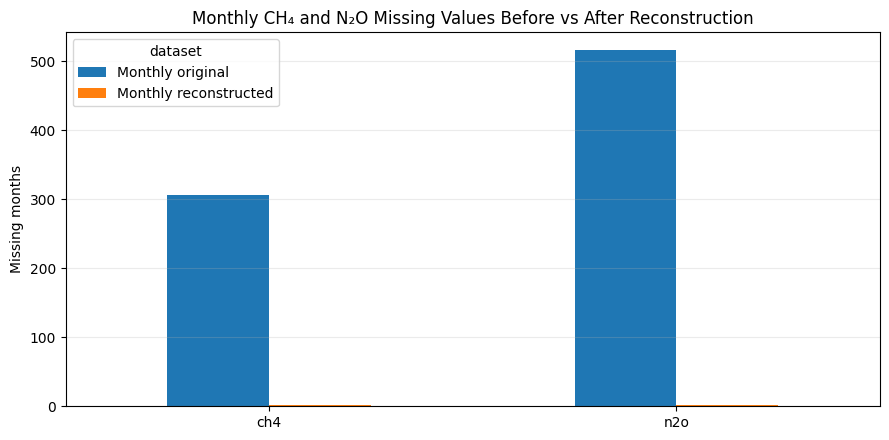

In [24]:
# Missingness audit before and after reconstruction.
monthly_audit_rows = []
for label, df in [
    ("Monthly original", monthly_original),
    ("Monthly reconstructed", monthly_reconstructed)
]:
    for col in ["temp_anomaly", "co2_monthly", "co2_trend", "sunspots",
                "nino34", "ch4", "n2o", "ch4_trend", "n2o_trend"]:
        if col in df.columns:
            monthly_audit_rows.append({
                "dataset": label,
                "variable": col,
                "rows": len(df),
                "missing_count": int(df[col].isna().sum()),
                "missing_percent": round(100 * df[col].isna().mean(), 2),
                "available_count": int(df[col].notna().sum())
            })

monthly_missing_audit = pd.DataFrame(monthly_audit_rows)
display(monthly_missing_audit)
monthly_missing_audit.to_csv(REPORT_DIR / "12_monthly_missingness_audit.csv", index=False)

focus = monthly_missing_audit[monthly_missing_audit["variable"].isin(["ch4", "n2o"])]
pivot = focus.pivot(index="variable", columns="dataset", values="missing_count")
ax = pivot.plot(kind="bar", figsize=(9, 4.5))
ax.set_title("Monthly CH₄ and N₂O Missing Values Before vs After Reconstruction")
ax.set_ylabel("Missing months")
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(REPORT_DIR / "12_monthly_missingness_before_after.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close()

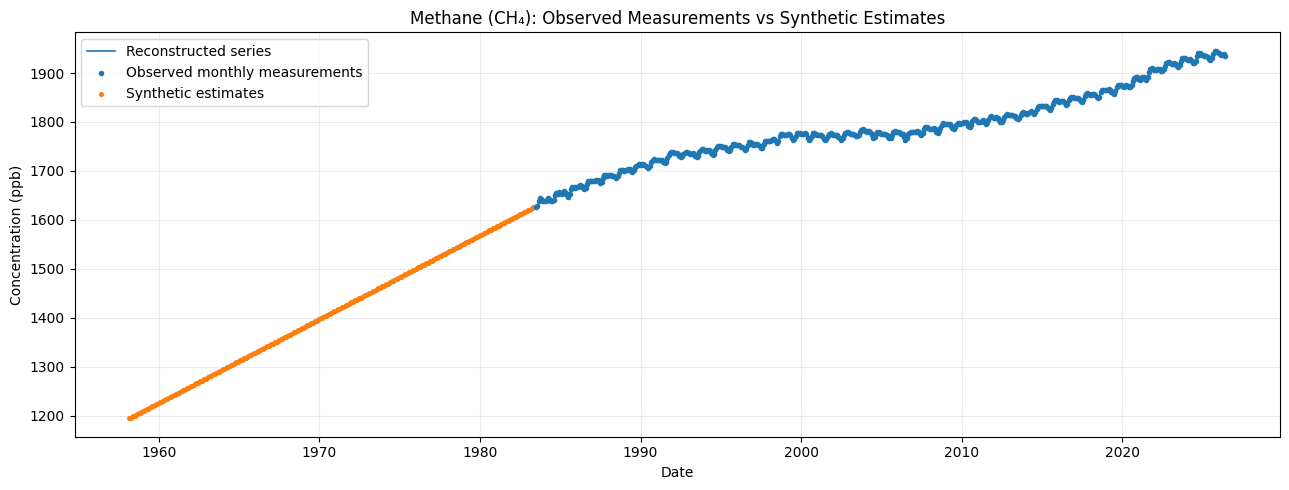

CH4 status counts:


ch4_reconstruction_status
observed_monthly             516
synthetic_annual_baseline    304
missing                        2
Name: count, dtype: int64

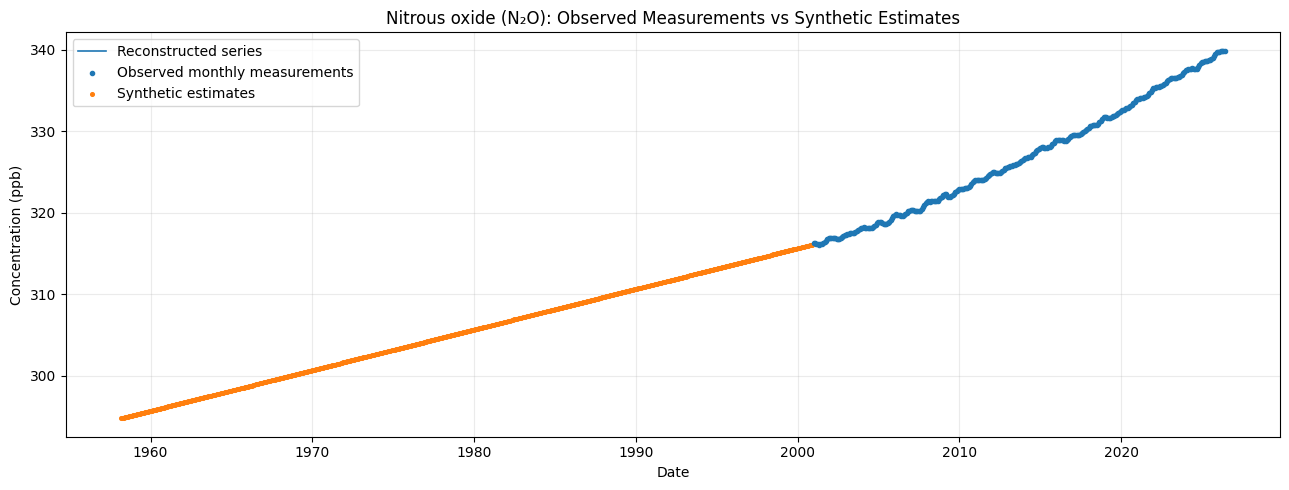

N2O status counts:


n2o_reconstruction_status
synthetic_annual_baseline    514
observed_monthly             306
missing                        2
Name: count, dtype: int64

In [25]:
# Plot observed measurements and synthetic estimates separately.
for gas, label, unit in [("ch4", "Methane (CH₄)", "ppb"), ("n2o", "Nitrous oxide (N₂O)", "ppb")]:
    if gas not in monthly_reconstructed.columns:
        continue
    observed = monthly_reconstructed[f"{gas}_original"].notna()
    synthetic = monthly_reconstructed[f"{gas}_is_synthetic"].fillna(False).astype(bool)

    fig, ax = plt.subplots(figsize=(13, 5))
    ax.plot(monthly_reconstructed["date"], monthly_reconstructed[gas],
            linewidth=1.2, label="Reconstructed series")
    ax.scatter(monthly_reconstructed.loc[observed, "date"],
               monthly_reconstructed.loc[observed, f"{gas}_original"],
               s=9, label="Observed monthly measurements", zorder=3)
    ax.scatter(monthly_reconstructed.loc[synthetic, "date"],
               monthly_reconstructed.loc[synthetic, gas],
               s=7, label="Synthetic estimates", zorder=2)
    ax.set_title(f"{label}: Observed Measurements vs Synthetic Estimates")
    ax.set_xlabel("Date")
    ax.set_ylabel(f"Concentration ({unit})")
    ax.grid(alpha=0.25)
    ax.legend()
    plt.tight_layout()
    fig.savefig(REPORT_DIR / f"13_monthly_{gas}_observed_vs_synthetic.png",
                dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"{gas.upper()} status counts:")
    display(monthly_reconstructed[f"{gas}_reconstruction_status"].value_counts(dropna=False))

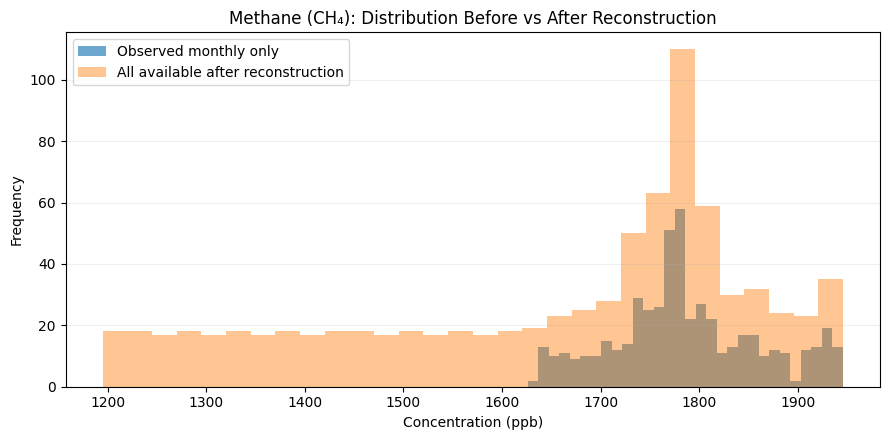

,observed_monthly_only,reconstructed_available
count,516.000000,820.000000
mean,1786.982674,1647.610224
std,75.202624,205.856289
min,1625.960000,1195.067485
25%,1741.235000,1486.956304
50%,1777.360000,1732.525000
75%,1834.745000,1794.195000
max,1945.510000,1945.510000


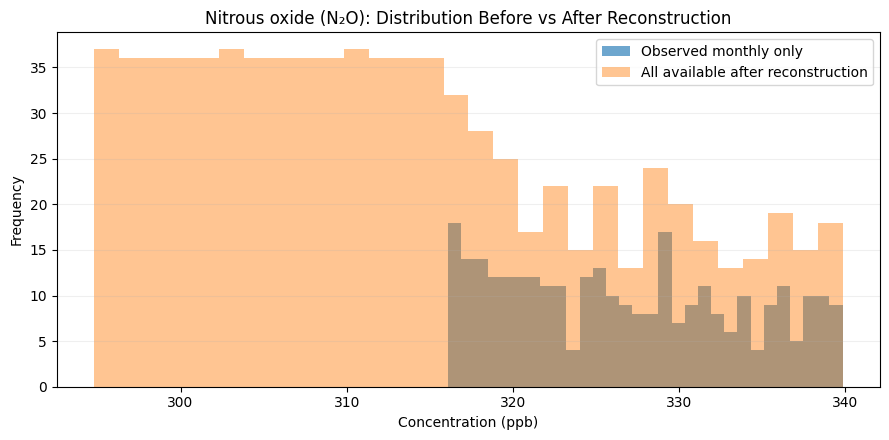

,observed_monthly_only,reconstructed_available
count,306.000000,820.000000
mean,326.806503,313.419377
std,7.060871,12.213437
min,316.110000,294.808867
25%,320.272500,303.302793
50%,326.125000,311.796719
75%,332.547500,322.165000
max,339.860000,339.860000


In [26]:
# Compare monthly distributions: observed values only vs all available reconstructed values.
for gas, label, unit in [("ch4", "Methane (CH₄)", "ppb"), ("n2o", "Nitrous oxide (N₂O)", "ppb")]:
    if gas not in monthly_reconstructed.columns:
        continue
    observed_vals = monthly_reconstructed[f"{gas}_original"].dropna()
    reconstructed_vals = monthly_reconstructed[gas].dropna()

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.hist(observed_vals, bins=30, alpha=0.65, label="Observed monthly only")
    ax.hist(reconstructed_vals, bins=30, alpha=0.45, label="All available after reconstruction")
    ax.set_title(f"{label}: Distribution Before vs After Reconstruction")
    ax.set_xlabel(f"Concentration ({unit})")
    ax.set_ylabel("Frequency")
    ax.legend()
    ax.grid(axis="y", alpha=0.2)
    plt.tight_layout()
    fig.savefig(REPORT_DIR / f"14_monthly_{gas}_distribution_comparison.png",
                dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    stats = pd.DataFrame({
        "observed_monthly_only": observed_vals.describe(),
        "reconstructed_available": reconstructed_vals.describe()
    })
    display(stats)
    stats.to_csv(REPORT_DIR / f"14_monthly_{gas}_distribution_stats.csv")

## Monthly correlations: observed-only vs reconstructed (exploratory)

Pearson correlation measures linear association, not causation. Climate time series are autocorrelated and often trend over time, so ordinary Pearson p-values can be overconfident and correlations between trending levels can be spurious. Pairwise sample counts are shown beside each coefficient.

The reconstructed-data heatmap is exploratory because synthetic values are generated estimates, not independent observations.

,temp_anomaly,co2_trend,sunspots,nino34,ch4,n2o
temp_anomaly,1.000000,0.931204,-0.135507,0.129299,0.880615,0.807169
co2_trend,0.931204,1.000000,-0.230457,-0.019851,0.974181,0.998562
sunspots,-0.135507,-0.230457,1.000000,0.060586,-0.048860,0.032006
nino34,0.129299,-0.019851,0.060586,1.000000,0.041613,0.038891
ch4,0.880615,0.974181,-0.048860,0.041613,1.000000,0.981825
n2o,0.807169,0.998562,0.032006,0.038891,0.981825,1.000000


,temp_anomaly,co2_trend,sunspots,nino34,ch4,n2o
temp_anomaly,822,822,822,820,516,306
co2_trend,822,822,822,820,516,306
sunspots,822,822,822,820,516,306
nino34,820,820,820,820,516,306
ch4,516,516,516,516,516,306
n2o,306,306,306,306,306,306


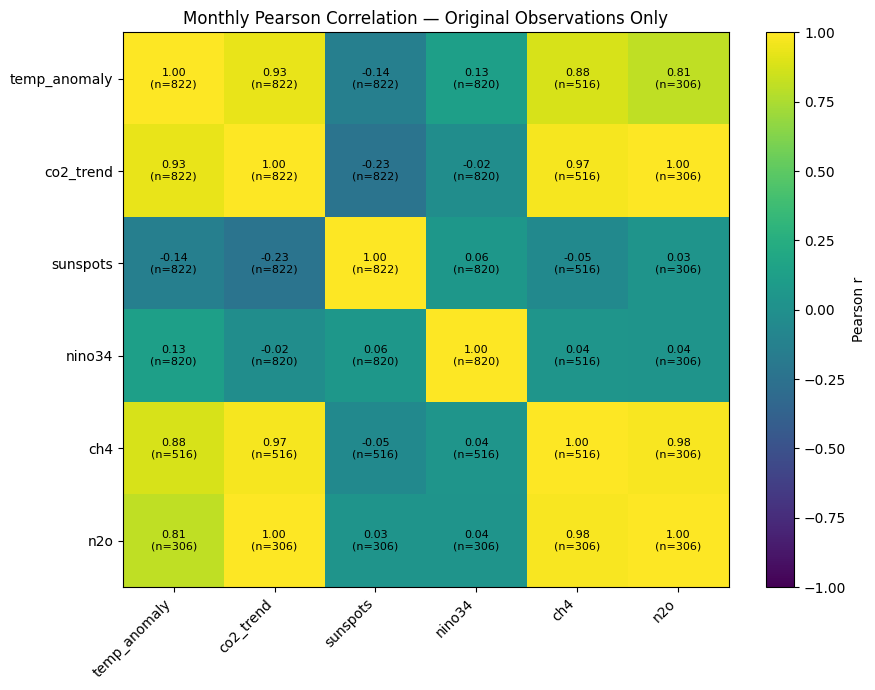

,temp_anomaly,co2_trend,sunspots,nino34,ch4,n2o
temp_anomaly,1.000000,0.931204,-0.135507,0.129299,0.841328,0.926697
co2_trend,0.931204,1.000000,-0.230457,-0.019851,0.920294,0.997923
sunspots,-0.135507,-0.230457,1.000000,0.060586,-0.201490,-0.229450
nino34,0.129299,-0.019851,0.060586,1.000000,-0.028280,-0.016932
ch4,0.841328,0.920294,-0.201490,-0.028280,1.000000,0.922241
n2o,0.926697,0.997923,-0.229450,-0.016932,0.922241,1.000000


,temp_anomaly,co2_trend,sunspots,nino34,ch4,n2o
temp_anomaly,822,822,822,820,820,820
co2_trend,822,822,822,820,820,820
sunspots,822,822,822,820,820,820
nino34,820,820,820,820,820,820
ch4,820,820,820,820,820,820
n2o,820,820,820,820,820,820


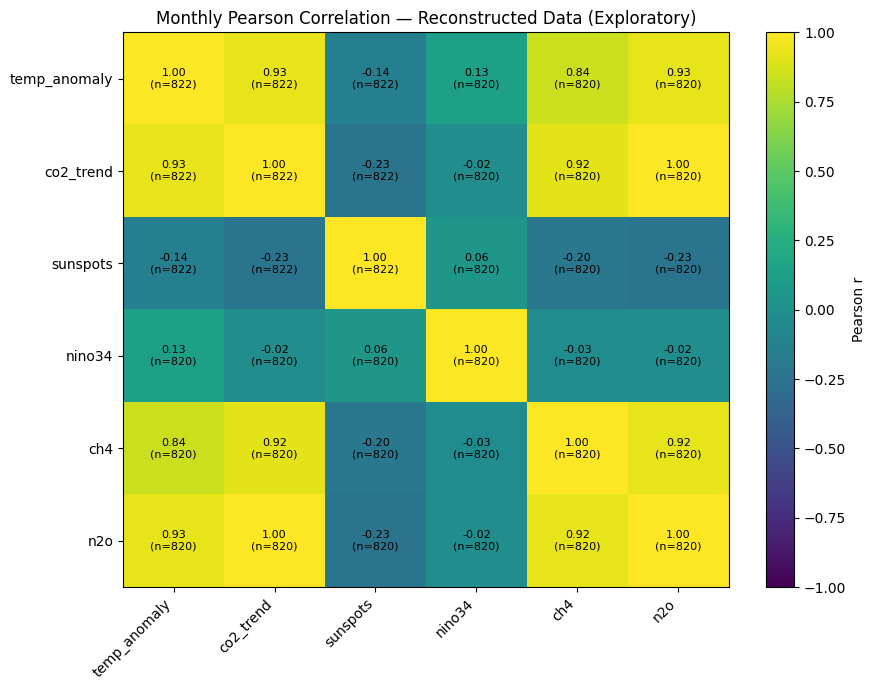

In [27]:
def correlation_and_pair_counts(df, columns):
    data = df[columns].apply(pd.to_numeric, errors="coerce")
    corr = data.corr(method="pearson")
    valid = data.notna().astype(int)
    counts = valid.T.dot(valid)
    return corr, counts

def plot_corr_counts(corr, counts, title, filename):
    fig, ax = plt.subplots(figsize=(9, 7))
    image = ax.imshow(corr.to_numpy(), vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(corr.columns)))
    ax.set_xticklabels(corr.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(corr.index)))
    ax.set_yticklabels(corr.index)
    for i in range(len(corr.index)):
        for j in range(len(corr.columns)):
            r = corr.iloc[i, j]
            n = counts.iloc[i, j]
            label = "NA" if pd.isna(r) else f"{r:.2f}\n(n={n})"
            ax.text(j, i, label, ha="center", va="center", fontsize=8)
    fig.colorbar(image, ax=ax, label="Pearson r")
    ax.set_title(title)
    plt.tight_layout()
    fig.savefig(REPORT_DIR / filename, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

monthly_corr_cols = [
    col for col in ["temp_anomaly", "co2_trend", "sunspots", "nino34", "ch4", "n2o"]
    if col in monthly_original.columns and col in monthly_reconstructed.columns
]

corr_original, counts_original = correlation_and_pair_counts(
    monthly_original, monthly_corr_cols
)
display(corr_original)
display(counts_original)
corr_original.to_csv(REPORT_DIR / "15_monthly_correlation_observed_only.csv")
counts_original.to_csv(REPORT_DIR / "15_monthly_correlation_observed_only_pair_counts.csv")
plot_corr_counts(
    corr_original, counts_original,
    "Monthly Pearson Correlation — Original Observations Only",
    "15_monthly_correlation_observed_only.png"
)

corr_reconstructed, counts_reconstructed = correlation_and_pair_counts(
    monthly_reconstructed, monthly_corr_cols
)
display(corr_reconstructed)
display(counts_reconstructed)
corr_reconstructed.to_csv(REPORT_DIR / "16_monthly_correlation_reconstructed_exploratory.csv")
counts_reconstructed.to_csv(REPORT_DIR / "16_monthly_correlation_reconstructed_pair_counts.csv")
plot_corr_counts(
    corr_reconstructed, counts_reconstructed,
    "Monthly Pearson Correlation — Reconstructed Data (Exploratory)",
    "16_monthly_correlation_reconstructed_exploratory.png"
)

,temp_anomaly,co2_trend,sunspots,nino34,ch4,n2o
temp_anomaly,1.000000,-0.009253,0.052579,0.106262,0.060200,0.026088
co2_trend,-0.009253,1.000000,-0.089394,-0.061859,0.021547,0.028363
sunspots,0.052579,-0.089394,1.000000,0.004253,-0.055929,-0.063052
nino34,0.106262,-0.061859,0.004253,1.000000,-0.063256,-0.066901
ch4,0.060200,0.021547,-0.055929,-0.063256,1.000000,0.372511
n2o,0.026088,0.028363,-0.063052,-0.066901,0.372511,1.000000


,temp_anomaly,co2_trend,sunspots,nino34,ch4,n2o
temp_anomaly,821,821,821,819,515,305
co2_trend,821,821,821,819,515,305
sunspots,821,821,821,819,515,305
nino34,819,819,819,819,515,305
ch4,515,515,515,515,515,305
n2o,305,305,305,305,305,305


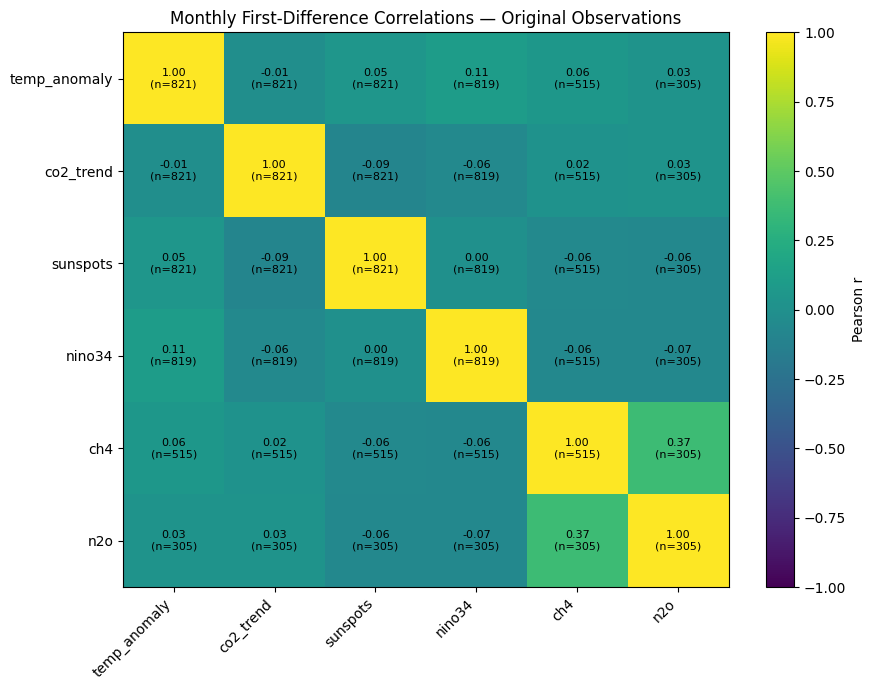

In [28]:
# Monthly first-difference correlations reduce shared linear trends.
# This is a diagnostic, not a complete correction for autocorrelation.
diff_data = monthly_original[monthly_corr_cols].apply(pd.to_numeric, errors="coerce").diff()
diff_corr = diff_data.corr()
diff_counts = diff_data.notna().astype(int).T.dot(diff_data.notna().astype(int))
display(diff_corr)
display(diff_counts)
diff_corr.to_csv(REPORT_DIR / "17_monthly_first_difference_correlation.csv")
diff_counts.to_csv(REPORT_DIR / "17_monthly_first_difference_pair_counts.csv")
plot_corr_counts(
    diff_corr, diff_counts,
    "Monthly First-Difference Correlations — Original Observations",
    "17_monthly_first_difference_correlation.png"
)

## CO₂ radiative forcing and lag diagnostic

Approximate forcing is calculated as \(F = 5.35\ln(C/C_0)\), using \(C_0=280\) ppm. This is a physically motivated approximation, not a full climate model. Lag correlations are descriptive: they do not establish causation, and the standard Pearson p-value does not account for serial autocorrelation or the fact that many lags are tested.

Rows used: 822
Date step days (most common): [31]


,min,max
mode,,
Levels,0.919659,0.928485
Linearly detrended,0.098019,0.493434


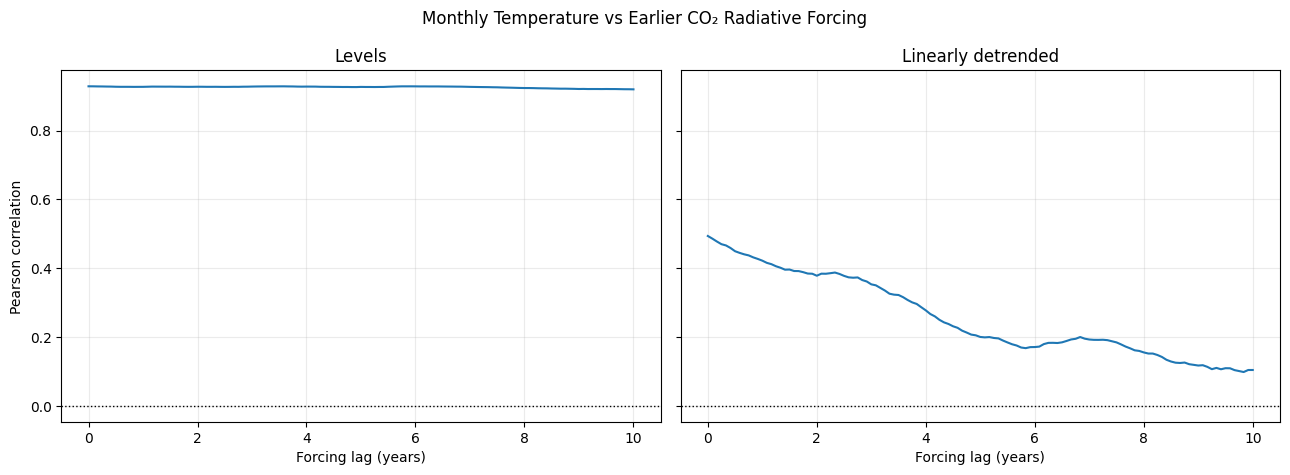

Saved EDA outputs to: /Users/sarachhabra/Climate-Change-Awareness-Dashboard/reports/eda_processed


In [29]:
from scipy.stats import pearsonr
from scipy.signal import detrend

monthly_lag = monthly_original.copy()
monthly_lag["co2_forcing"] = 5.35 * np.log(monthly_lag["co2_trend"] / 280)
valid = monthly_lag[["date", "temp_anomaly", "co2_forcing"]].dropna().copy()

# This series is expected to be continuous in the current source table.
# If dates are not monthly-contiguous, do not interpret shift(lag) as exact months.
date_steps = valid["date"].diff().dropna().dt.days
print("Rows used:", len(valid))
print("Date step days (most common):", date_steps.mode().tolist())

valid["temp_detrended"] = detrend(valid["temp_anomaly"].to_numpy())
valid["forcing_detrended"] = detrend(valid["co2_forcing"].to_numpy())

lag_rows = []
for lag in range(0, 121):
    for mode, ycol, xcol in [
        ("Levels", "temp_anomaly", "co2_forcing"),
        ("Linearly detrended", "temp_detrended", "forcing_detrended")
    ]:
        pair = pd.concat(
            [valid[ycol], valid[xcol].shift(lag)], axis=1
        ).dropna()
        if len(pair) >= 100:
            r, p = pearsonr(pair.iloc[:, 0], pair.iloc[:, 1])
            lag_rows.append({
                "mode": mode, "lag_months": lag, "lag_years": lag / 12,
                "correlation": r, "p_value_naive": p, "n": len(pair)
            })

lag_results = pd.DataFrame(lag_rows)
display(lag_results.groupby("mode")["correlation"].agg(["min", "max"]))
lag_results.to_csv(REPORT_DIR / "18_monthly_co2_forcing_lag_results.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, mode in zip(axes, ["Levels", "Linearly detrended"]):
    subset = lag_results[lag_results["mode"] == mode]
    ax.plot(subset["lag_years"], subset["correlation"])
    ax.axhline(0, color="black", linewidth=1, linestyle=":")
    ax.set_title(mode)
    ax.set_xlabel("Forcing lag (years)")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Pearson correlation")
fig.suptitle("Monthly Temperature vs Earlier CO₂ Radiative Forcing")
plt.tight_layout()
fig.savefig(REPORT_DIR / "18_monthly_co2_forcing_lag_diagnostic.png",
            dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved EDA outputs to:", REPORT_DIR)

## EDA completion checklist

Before moving to feature engineering, confirm:
- [ ] The notebook runs from top to bottom without errors in the project environment.
- [ ] `climate_annual.csv` and `climate_monthly.csv` remain unchanged; reconstructed data is saved to separate files.
- [ ] Observed monthly CH₄/N₂O values are preserved and synthetic estimates are flagged.
- [ ] Validation metrics are described as short-gap interpolation diagnostics, **not** proof that historical annual-baseline monthly estimates are accurate.
- [ ] Correlations and lag plots are described as exploratory, not causal evidence.

**Handoff to feature engineering:** use the original observed dataset for baseline analysis and the reconstructed files only where the modelling plan explicitly permits synthetic estimates. Keep reconstruction flags/status columns so models can exclude or separately assess synthetic inputs. Do not treat the smooth annual-baseline estimates as real monthly observations.